In [29]:
import numpy as np
import scipy.stats

import corner
import emcee
import dynesty

import matplotlib.pyplot as plt

In [30]:
title = "# week 6 - Solutions: Nested sampling and slice sampling"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# week 6 - Solutions: Nested sampling and slice sampling

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

We use the two targets from last week: the 1D Gamma distribution from the lecture and the 2D Gaussian from the Metropolis-Hastings exercise.

In [31]:
# 1D target from the lecture
target_distr_1d = scipy.stats.gamma(a=3, scale=1/3)

# 2D Gaussian from the Metropolis-Hastings exercise
sigma_x = 1
sigma_y = 2
rho = 0.7

mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Exact samples, to compare your samplers against
np.random.seed(42)
true_samples = bivariate_normal.rvs(size=10_000)

Text(0.5, 1.0, '2D Gaussian target (exact samples)')

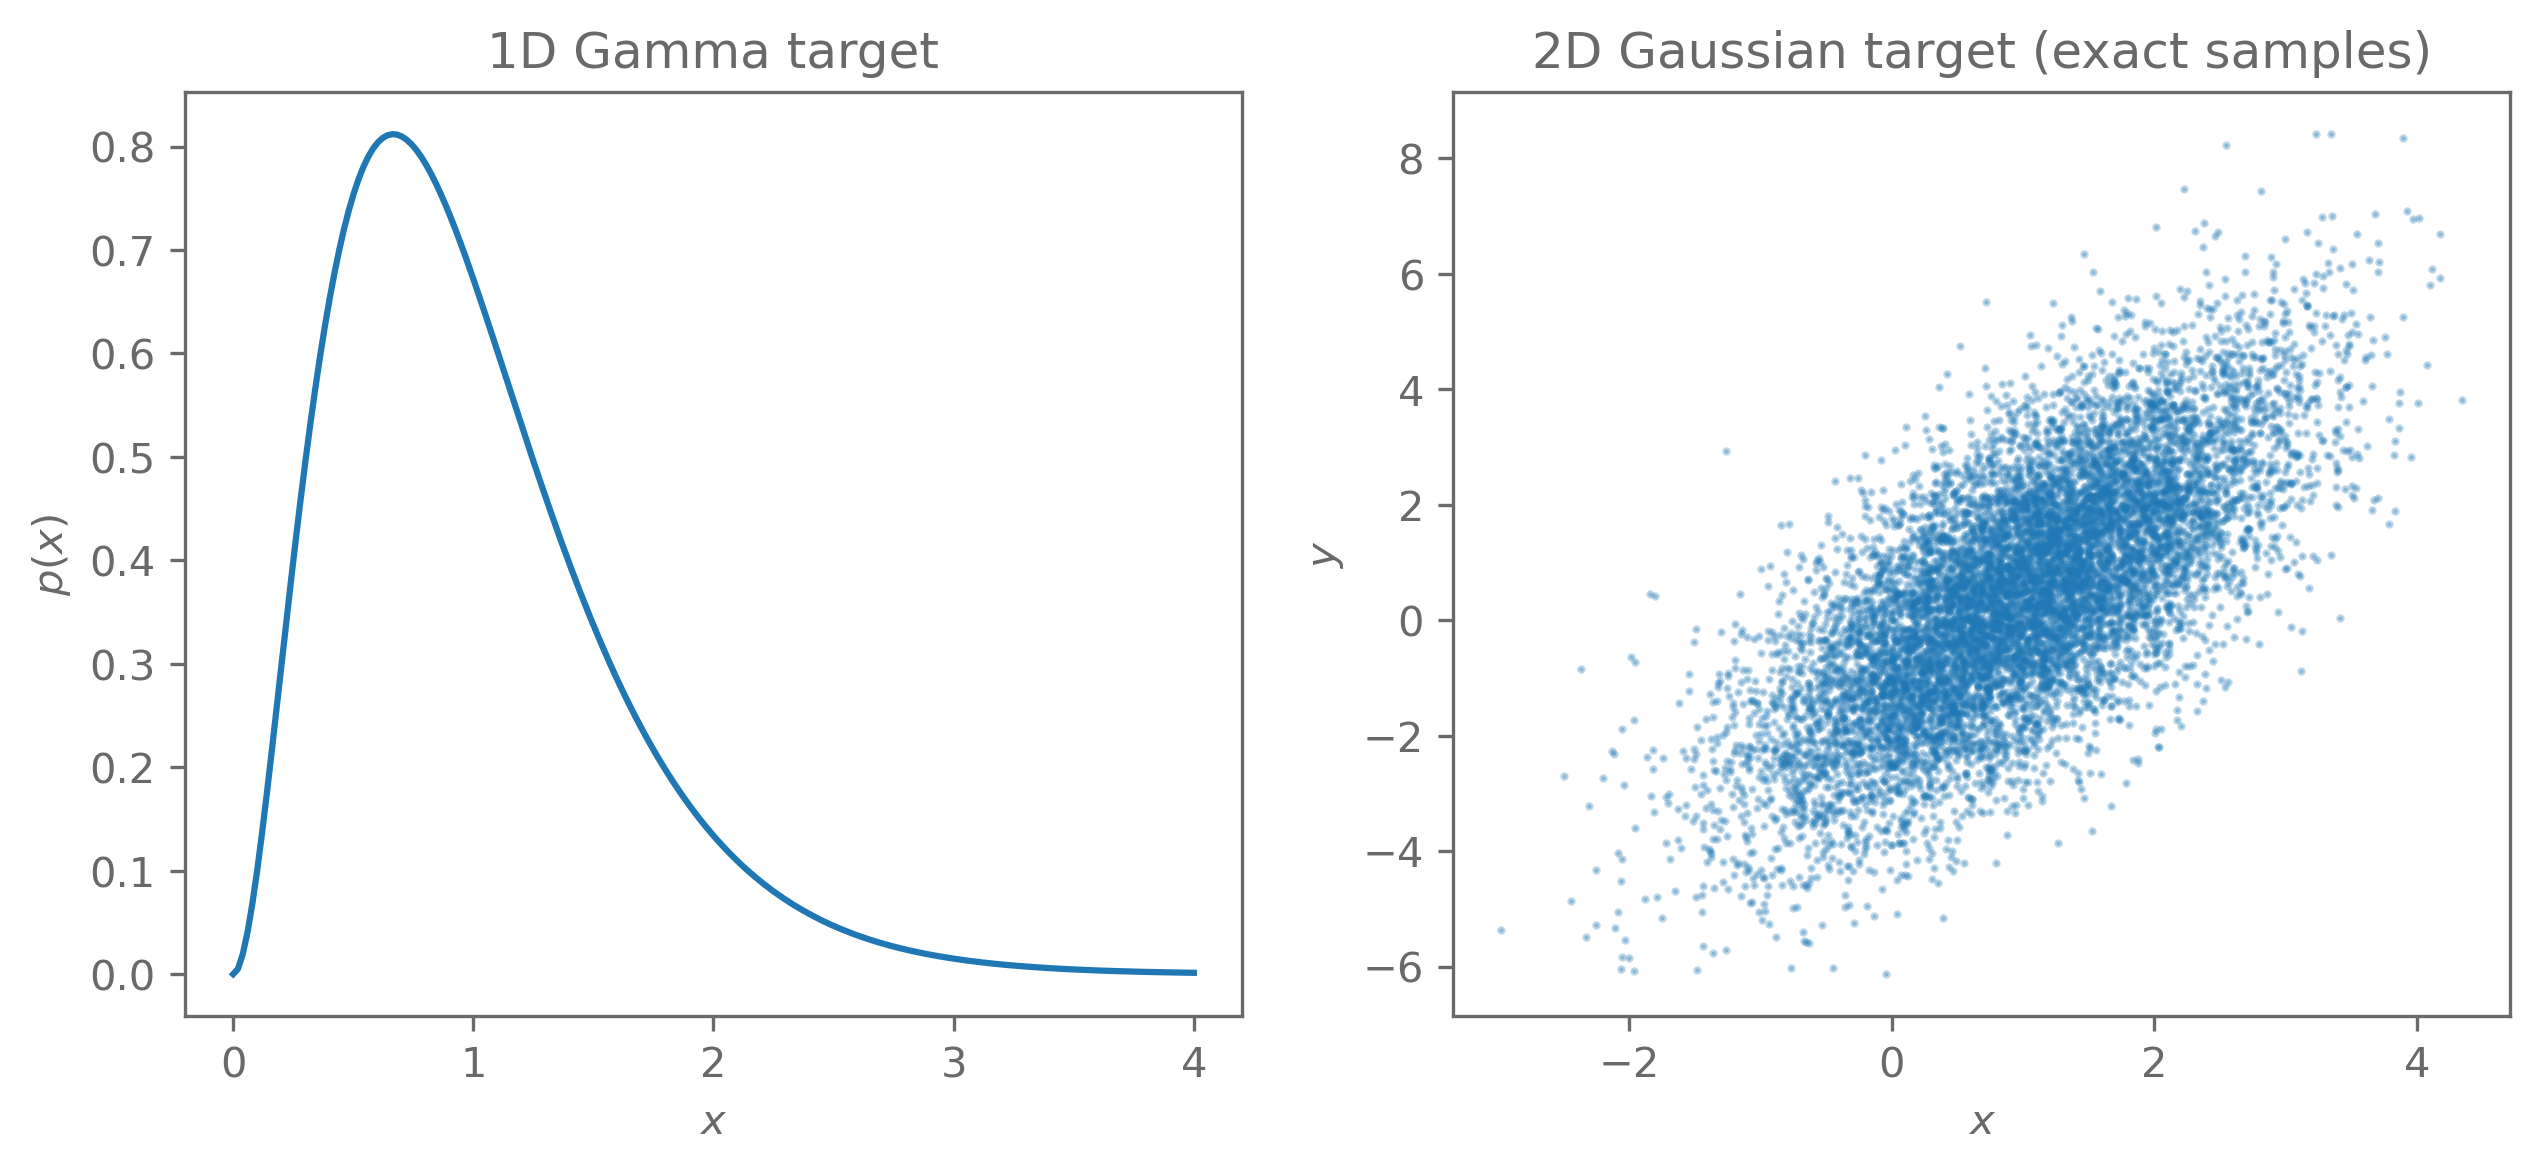

In [32]:
fig, (ax_1d, ax_2d) = plt.subplots(1, 2, figsize=(10, 4))

# 1D Gamma target
grid = np.linspace(0, 4, 200)
ax_1d.plot(grid, target_distr_1d.pdf(grid))
ax_1d.set_xlabel("$x$")
ax_1d.set_ylabel("$p(x)$")
ax_1d.set_title("1D Gamma target")

# 2D Gaussian target, shown with the exact samples
ax_2d.scatter(*true_samples.T, s=1, alpha=0.3)
ax_2d.set_xlabel("$x$")
ax_2d.set_ylabel("$y$")
ax_2d.set_title("2D Gaussian target (exact samples)")


A small helper to overplot several sets of samples in one corner plot:

In [33]:
def compare_corner(sample_sets, labels, weights=None):
    """Overplot several sets of 2D samples in one corner plot."""
    if weights is None:
        weights = [None]*len(sample_sets)

    fig = plt.figure()
    for i, (samples, w) in enumerate(zip(sample_sets, weights)):
        if w is None:
            w = np.ones(len(samples))   # equally weighted samples
        corner.corner(
            samples, weights=w/np.sum(w),
            bins=25, smooth=1.0, color=f"C{i}",  # light smoothing for fewer, noisy samples
            range=[(-3, 5), (-6, 7)],
            levels=1-np.exp(-0.5*np.array([1, 2])**2),  # 1 and 2 sigma contours in 2D
            labels=["$x$", "$y$"],
            fig=fig,
        )
    # Add a legend
    for i, label in enumerate(labels):
        fig.axes[0].plot([], [], c=f"C{i}", label=label)
    fig.axes[0].legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False)
    return fig

---
## Exercise 0: Why slice sampling?

*Nothing to implement here: read this and run the cell below.*

Last week we saw two ways to sample from a distribution $p(x)$:
- **Rejection sampling** gives independent samples, but needs a proposal $q$ and a constant $M$ with $Mq(x) > p(x)$ everywhere. In many dimensions almost every point is rejected.
- **Metropolis-Hastings** works in many dimensions, but you have to choose the proposal width. Too small, and the chain moves very slowly; too large, and almost every jump is rejected. The right width depends on $p$, which you do not know beforehand.

**Slice sampling** keeps the Markov chain approach of Metropolis-Hastings, but removes most of the tuning:
- It uses the same idea as rejection sampling: points spread uniformly under the curve $p(x)$ give samples of $p$.
- Each step picks a random height $u$ below $p(x_t)$, then a new point $x_{t+1}$ from the *slice*, where $p(x) > u$ (see the plot below).
- The interval that searches for the slice adapts by itself: it grows if it is too small and shrinks if it is too large. The step size $w$ only changes the speed, not the result.
- No step is wasted: the chain always moves to a new point.

**When to use it:** problems with a few to a moderate number of parameters, when you do not want to tune a proposal. It is also used inside nested sampling codes to find new live points (Exercises 3 and 4).

**When not:** for strongly correlated parameters, updating one coordinate at a time is slow. For very many parameters, methods that use gradients, like Hamiltonian Monte Carlo, work better.

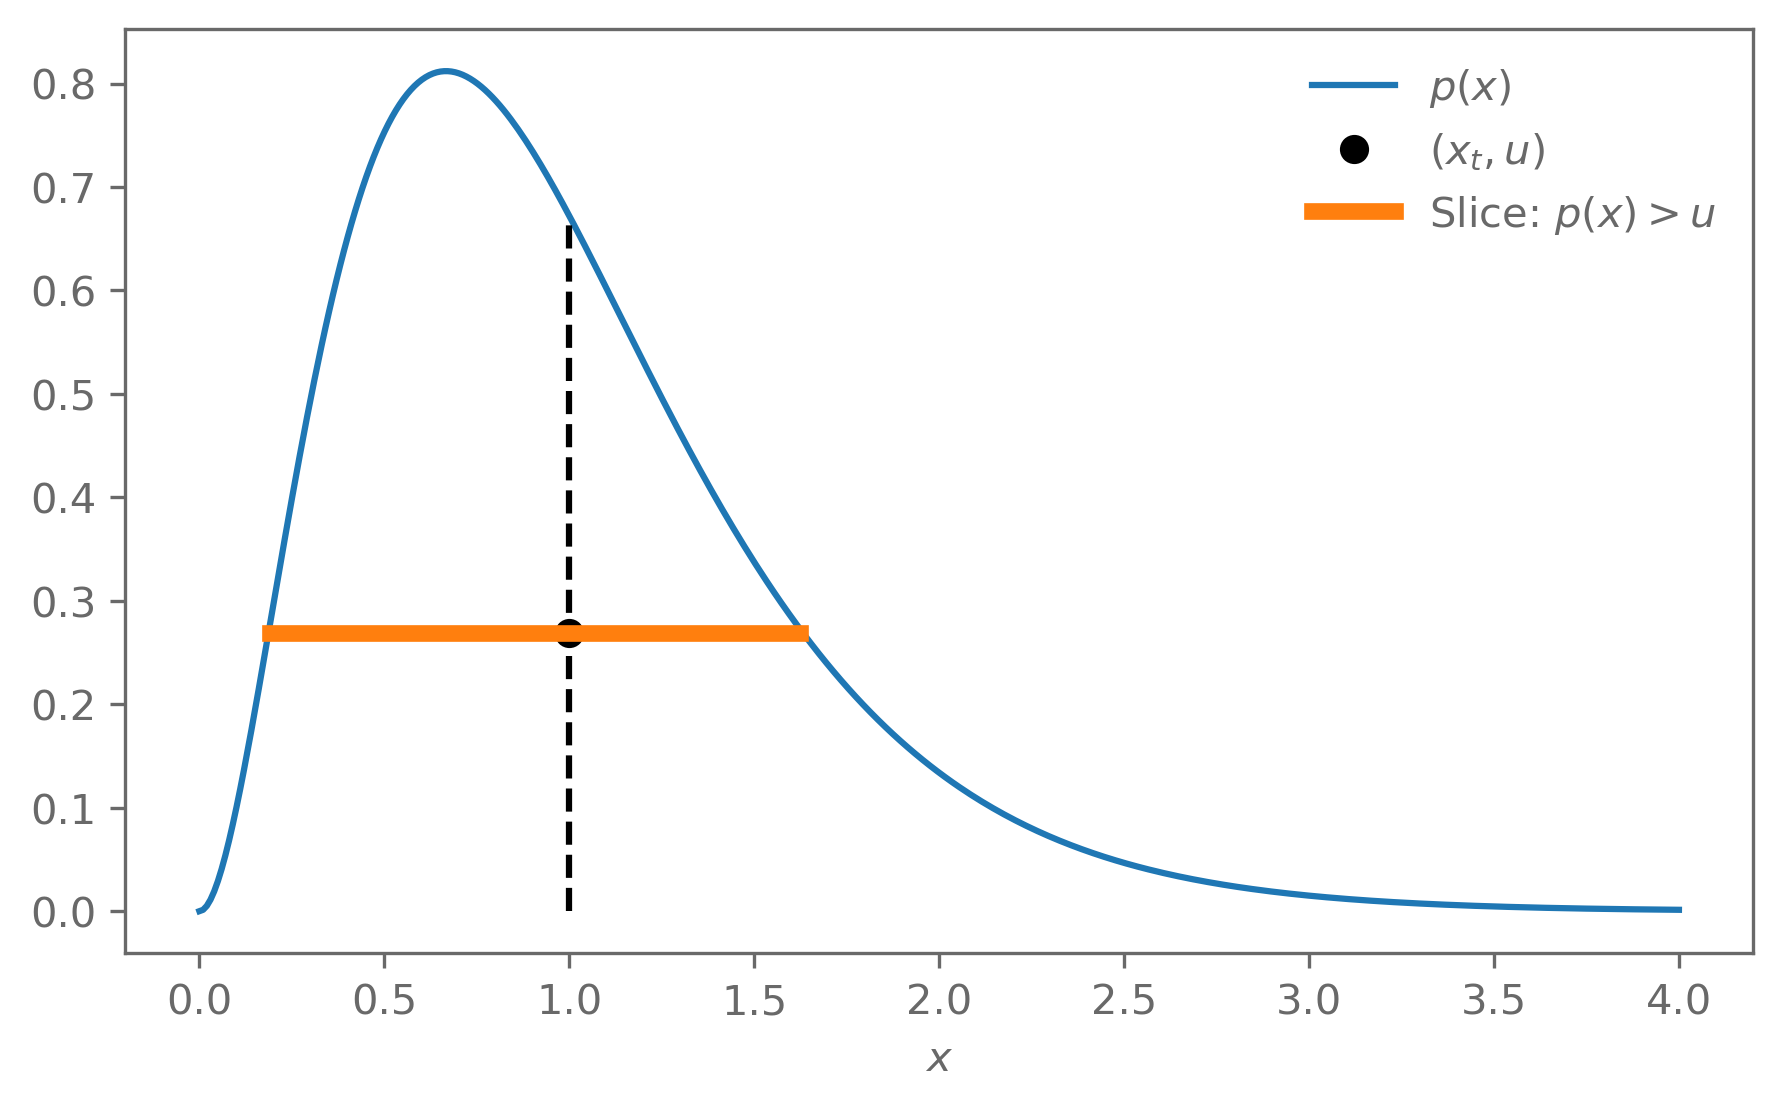

In [34]:
grid = np.linspace(0, 4, 400)
p = target_distr_1d.pdf(grid)

x_t = 1.0                          # current point of the chain
u = 0.4*target_distr_1d.pdf(x_t)   # a height below p(x_t)
in_slice = p > u                   # the slice: all x where p(x) > u

plt.plot(grid, p, label="$p(x)$")
plt.vlines(x_t, 0, target_distr_1d.pdf(x_t), color="k", ls="--")
plt.plot(x_t, u, "ko", label="$(x_t, u)$")
plt.plot(grid[in_slice], np.full(np.sum(in_slice), u), c="C1", lw=4,
         label="Slice: $p(x) > u$")
plt.xlabel("$x$")
plt.legend(frameon=False)

---
## Exercise 1: Slice sampling

### 1.1 Slice sampling in 1D

We follow the algorithm from the lecture, but work with $\ln p(x)$. The height of the slice is then $\ln u = \ln p(x_t) + \ln v$, with $v\sim\mathcal{U}(0, 1)$.

We write one update as its own function, `slice_step`, and call it $n$ times.

In [35]:
def slice_step(log_p, x, w):
    """One slice sampling update of the 1D point x, with step size w."""
    # 1. Height of the slice, in log space
    log_u = log_p(x) + np.log(np.random.uniform())

    # 2. Place an interval of width w randomly around x ...
    r = np.random.uniform()
    left = x - r*w
    right = x + (1 - r)*w
    # ... and step out until both ends are outside the slice
    while log_p(left) > log_u:
        left = left - w
    while log_p(right) > log_u:
        right = right + w

    # 3. Draw a point in the interval. If it is outside the slice,
    # shrink the interval towards x and try again
    while True:
        x_new = np.random.uniform(left, right)
        if log_p(x_new) > log_u:
            return x_new       # inside the slice: accept
        if x_new > x:
            right = x_new
        else:
            left = x_new


def slice_sample_1d(log_p, x0, w, n):
    """Draw n samples with slice sampling, starting at x0."""
    samples = np.zeros(n)
    x = x0
    for i in range(n):
        x = slice_step(log_p, x, w)
        samples[i] = x
    return samples

To see how much work the sampler does, we count the evaluations of $\ln p(x)$ with a global counter:

In [36]:
n_evals = 0

def log_p_gamma(x):
    """Log PDF of the Gamma target. Also counts the number of calls."""
    global n_evals
    n_evals += 1
    return target_distr_1d.logpdf(x)

Evaluations of p(x) per sample: 6.2


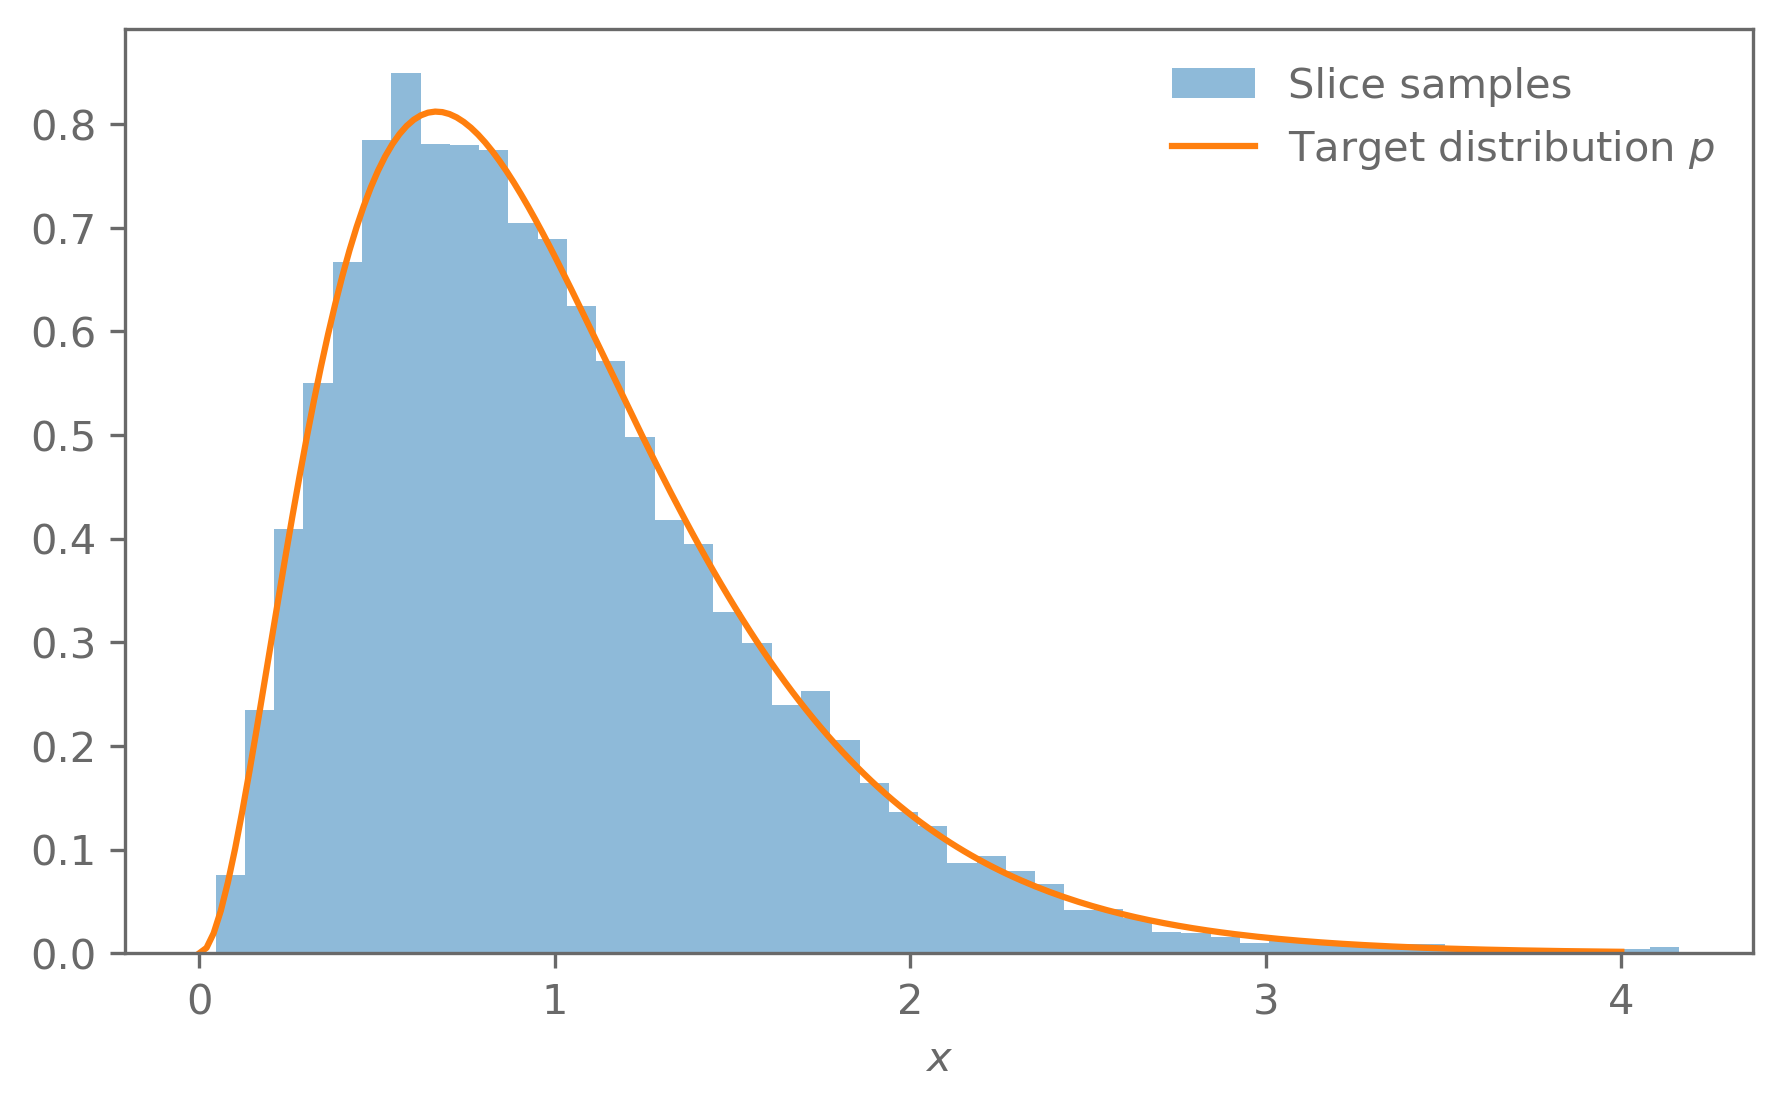

In [37]:
np.random.seed(1)

n_evals = 0
samples = slice_sample_1d(log_p_gamma, x0=1.0, w=1, n=10_000)
print(f"Evaluations of p(x) per sample: {n_evals/len(samples):.1f}")

grid = np.linspace(0, 4, 200)
plt.hist(samples, bins=50, density=True, alpha=0.5, label="Slice samples")
plt.plot(grid, target_distr_1d.pdf(grid), label="Target distribution $p$")
plt.xlabel("$x$")
plt.legend(frameon=False);

The samples follow the PDF.

### 1.2 The step size $w$

We run the sampler again with $w = 0.01, 1, 100$:

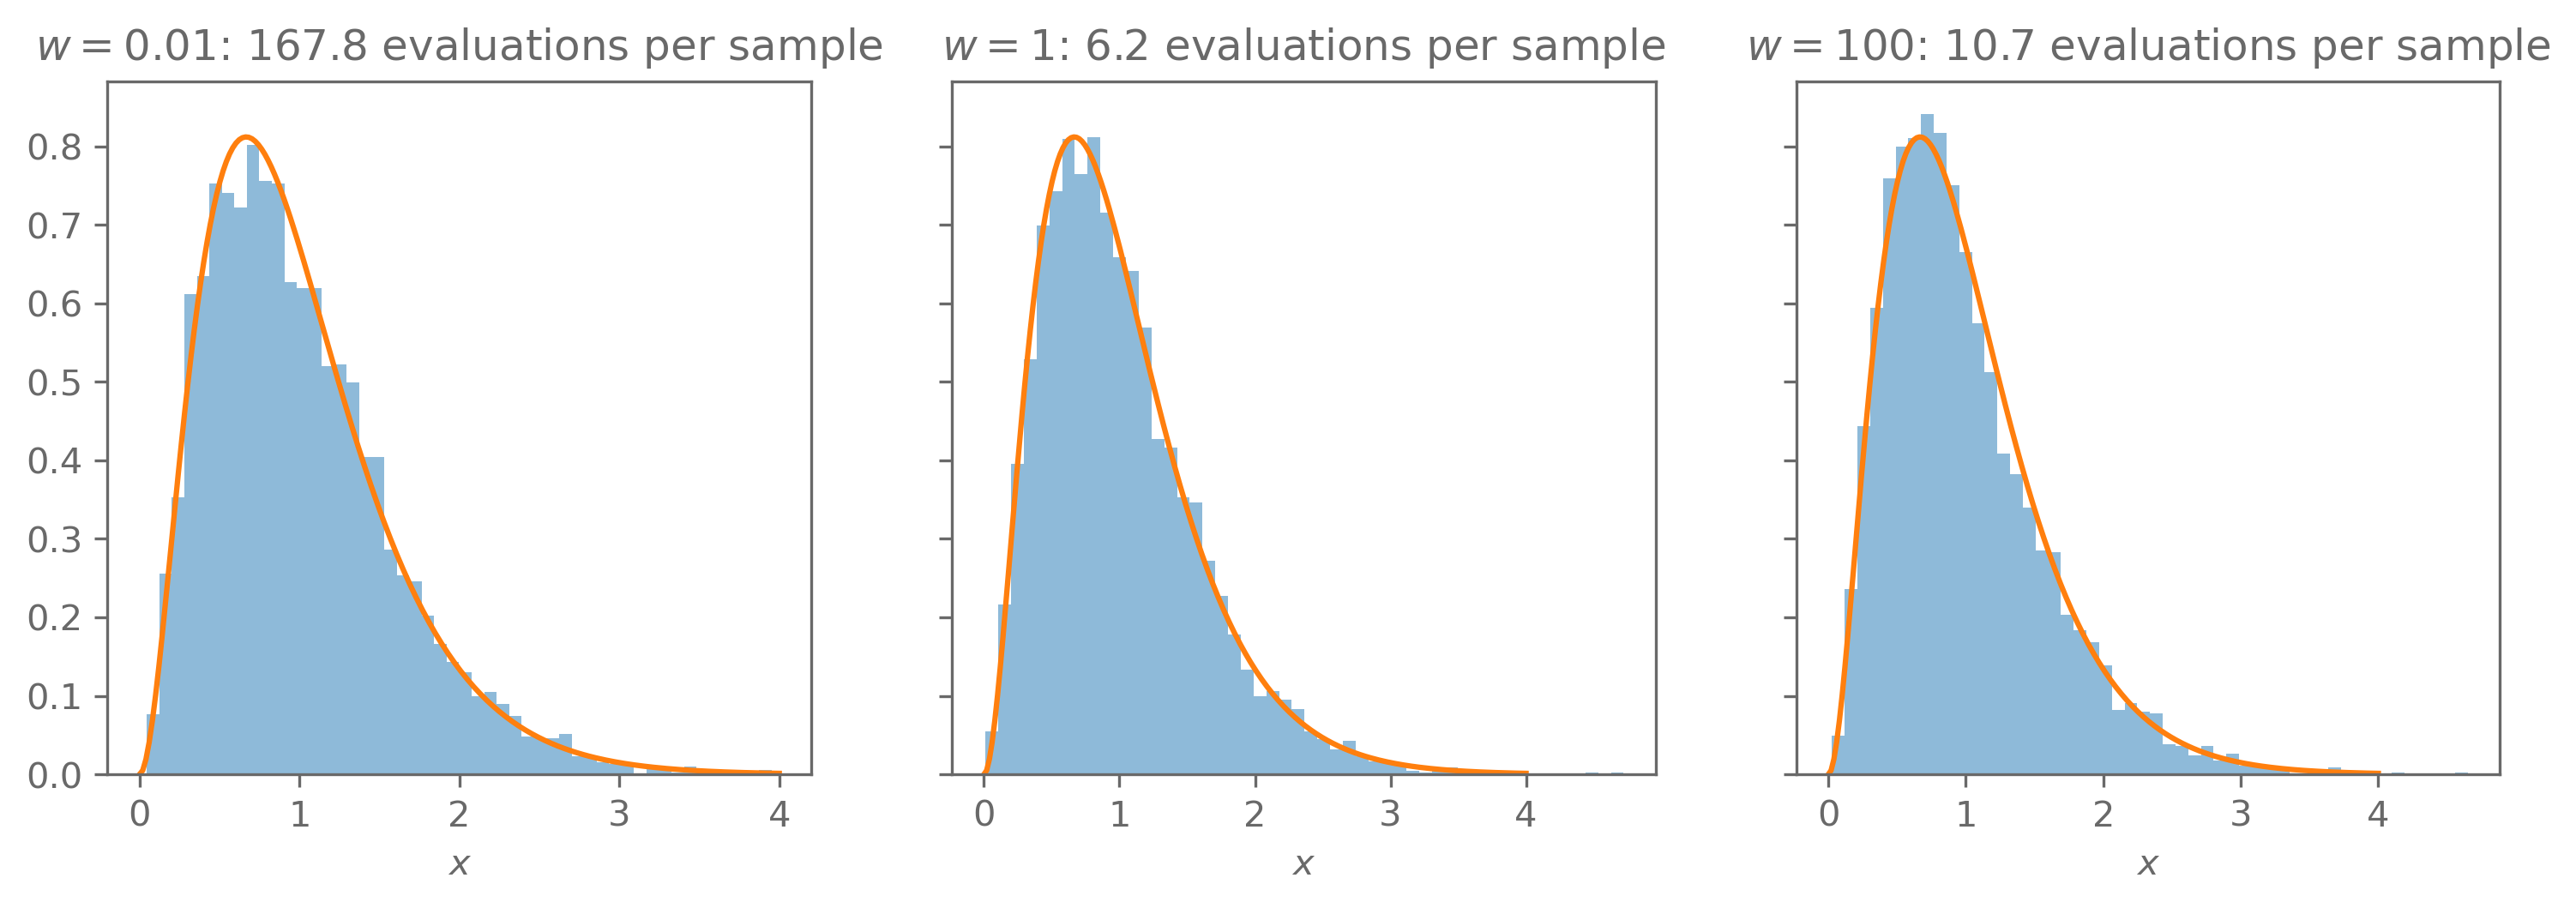

In [40]:
np.random.seed(2)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, w in zip(axes, [0.01, 1, 100]):
    n_evals = 0
    samples = slice_sample_1d(log_p_gamma, x0=1.0, w=w, n=5000)

    ax.hist(samples, bins=50, density=True, alpha=0.5)
    ax.plot(grid, target_distr_1d.pdf(grid))
    ax.set_title(f"$w={w}$: {n_evals/len(samples):.1f} evaluations per sample")
    ax.set_xlabel("$x$")

All three step sizes give the correct distribution, only the cost changes:
- $w = 0.01$: many stepping-out steps, because the interval grows very slowly.
- $w = 100$: many shrinking steps, because the interval starts far too wide.
- $w = 1$, close to the width of the distribution, is the cheapest.

---
## Exercise 2: Burn-in and auto-correlation

### 2.1 Starting far in the tail

For Metropolis-Hastings we use a short version of `run_metropolis` from the week 5 solutions, with a Gaussian proposal around the current point. This proposal is symmetric, so we accept with probability $\min(1, p(x')/p(x_t))$.

We start both samplers far in the tail of the Gamma distribution, at $x = 10$.

In [41]:
def metropolis_hastings(log_p, x0, step, n):
    """Metropolis-Hastings in 1D with a Gaussian proposal of width step around the current point."""
    x = x0
    log_p_x = log_p(x)
    samples = np.zeros(n)
    n_accept = 0
    for i in range(n):
        # Propose a new point around the current one
        x_new = x + step*np.random.normal()
        log_p_new = log_p(x_new)

        # Accept with probability min(1, p(x_new)/p(x))
        if np.log(np.random.uniform()) < log_p_new - log_p_x:
            x = x_new
            log_p_x = log_p_new
            n_accept += 1
        samples[i] = x
    print(f"Acceptance rate: {n_accept/n:.2f}")
    return samples

In [42]:
np.random.seed(4)
x_start = 10
n_steps = 20_000

n_evals = 0
mh_chain = metropolis_hastings(log_p_gamma, x_start, step=1, n=n_steps)
mh_evals_per_step = n_evals/n_steps

n_evals = 0
slice_chain = slice_sample_1d(log_p_gamma, x_start, w=1, n=n_steps)
slice_evals_per_step = n_evals/n_steps

print(f"Evaluations of p(x) per step: MH {mh_evals_per_step:.1f}, slice {slice_evals_per_step:.1f}")

Acceptance rate: 0.51
Evaluations of p(x) per step: MH 1.0, slice 6.2


The first 200 steps of each chain. The dashed line shows the mean of the target.

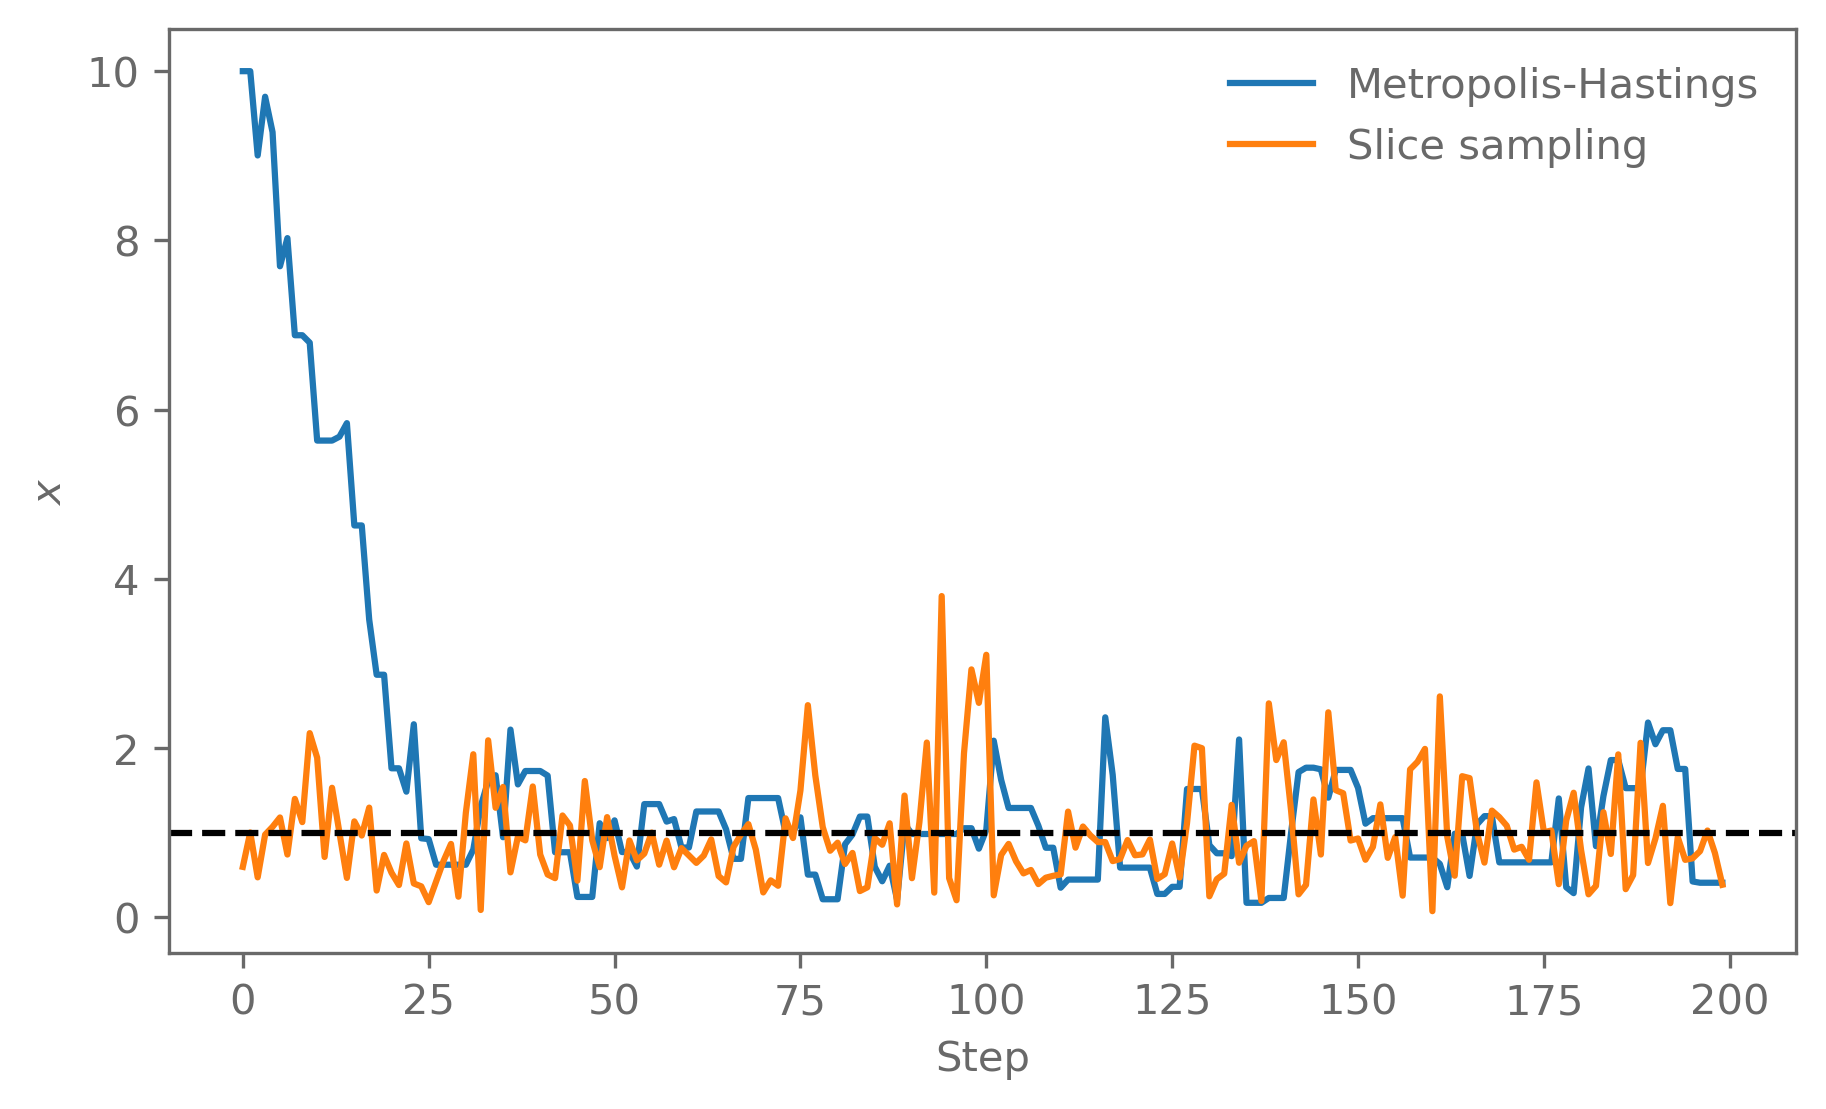

In [43]:
plt.plot(mh_chain[:200], label="Metropolis-Hastings")
plt.plot(slice_chain[:200], label="Slice sampling")
plt.axhline(target_distr_1d.mean(), c="k", ls="--")
plt.xlabel("Step")
plt.ylabel("$x$")
plt.legend(frameon=False);

Metropolis-Hastings needs about 25 steps to walk down from $x = 10$ to the bulk of the distribution. Slice sampling gets there in the first step, because stepping out finds the whole slice at once. To be safe, we remove the first 1000 steps as burn-in.

The Metropolis-Hastings chain often stays at the same point (rejected proposals), while the slice sampling chain moves in every step.

### 2.2 Auto-correlation time

A chain of $N$ steps has about $N/\tau$ independent samples.

In [44]:
burn_in = 1000

for name, chain in [("Metropolis-Hastings", mh_chain), ("Slice sampling", slice_chain)]:
    chain = chain[burn_in:]
    tau = emcee.autocorr.integrated_time(chain)[0]
    print(f"{name}: tau = {tau:.1f}, about {len(chain)/tau:.0f} independent samples")

Metropolis-Hastings: tau = 6.2, about 3083 independent samples
Slice sampling: tau = 1.6, about 12066 independent samples


Slice sampling has a shorter auto-correlation time, so it gives about 4 times more independent samples per step.

But each slice step needs about 6 evaluations of $p(x)$, while Metropolis-Hastings needs only one. Per evaluation of $p(x)$, Metropolis-Hastings with a well-chosen step size is even a bit more efficient here. The advantage of slice sampling is that it works without tuning.

---
## Exercise 3: Nested sampling

### 3.1 Implementation

We follow the algorithm from the lecture, with two simplifications:
- New live points come from rejection sampling: draw from the prior until $L(\theta) > L_i^*$.
- Each dead point gets the weight $\Delta X_i = X_{i-1} - X_i$ instead of the trapezoidal rule, with $X_i = t^i$ and $t = n_\mathrm{live}/(n_\mathrm{live}+1)$.

We stop when the live points can add less than 1% to $Z$, and then add the remaining live points, each with weight $X_i/n_\mathrm{live}$. Everything is done in log space: `np.logaddexp(a, b)` computes $\ln(e^a + e^b)$.

In [45]:
def nested_sampling(log_L, prior_sample, n_live, tol=0.01):
    """Nested sampling with rejection sampling from the prior.

    Returns log Z, the dead points, their posterior weights, and the
    number of tries needed to find each new live point.
    """
    # 1. Live points from the prior
    live_points = prior_sample(n_live)
    live_log_L = np.array([log_L(theta) for theta in live_points])

    log_t = np.log(n_live/(n_live + 1))   # volume shrinks by t each iteration
    log_X = 0.0                           # X_0 = 1
    log_Z = -np.inf                       # Z = 0 at the start

    dead_points, dead_log_L, dead_log_dX = [], [], []
    n_tries = []

    while True:
        # 2. The live point with the lowest likelihood becomes a dead point
        i_min = np.argmin(live_log_L)
        log_L_star = live_log_L[i_min]

        # 4. Its weight is Delta X = X_{i-1} - X_i = X_{i-1} (1 - t)
        log_dX = log_X + np.log(1 - np.exp(log_t))
        log_Z = np.logaddexp(log_Z, log_L_star + log_dX)
        log_X = log_X + log_t

        dead_points.append(live_points[i_min].copy())
        dead_log_L.append(log_L_star)
        dead_log_dX.append(log_dX)

        # 3. Replace it with a prior sample with a higher likelihood
        tries = 0
        while True:
            theta = prior_sample(1)[0]
            log_L_new = log_L(theta)
            tries += 1
            if log_L_new > log_L_star:
                break
        live_points[i_min] = theta
        live_log_L[i_min] = log_L_new
        n_tries.append(tries)

        # 5. Stop if the live points can only add a small fraction to Z
        if np.max(live_log_L) + log_X < np.log(tol) + log_Z:
            break

    # Add the remaining live points, each with weight X/n_live
    for theta, log_L_live in zip(live_points, live_log_L):
        log_dX = log_X - np.log(n_live)
        log_Z = np.logaddexp(log_Z, log_L_live + log_dX)
        dead_points.append(theta)
        dead_log_L.append(log_L_live)
        dead_log_dX.append(log_dX)

    # Posterior weights p_i = L_i Delta X_i / Z
    weights = np.exp(np.array(dead_log_L) + np.array(dead_log_dX) - log_Z)

    return log_Z, np.array(dead_points), weights, np.array(n_tries)

Likelihood: the 2D Gaussian. Prior: uniform on $[-7, 7]^2$.

In [46]:
def log_L_gauss(theta):
    return bivariate_normal.logpdf(theta)

def prior_sample_box(n):
    """n samples from the uniform prior on [-7, 7]^2."""
    return np.random.uniform(-7, 7, size=(n, 2))

np.random.seed(5)
log_Z, dead_points, ns_weights, n_tries = nested_sampling(
    log_L_gauss, prior_sample_box, n_live=200)
print(f"Nested sampling: ln Z = {log_Z:.3f}")

Nested sampling: ln Z = -5.287


### 3.2 Exact evidence

The prior is $1/14^2$ inside the box, and almost all of the Gaussian lies inside the box, so
$$
    Z = \frac{1}{14^2}\int_\mathrm{box} L(\theta)\,\mathrm{d}\theta \approx \frac{1}{14^2}\,.
$$
We check that the Gaussian is inside the box with the exact samples:

In [47]:
inside_box = np.all(np.abs(true_samples) < 7, axis=1)
print(f"Fraction of the Gaussian inside the box: {np.mean(inside_box):.4f}")

log_Z_exact = -np.log(14**2)
print(f"Exact:           ln Z = {log_Z_exact:.3f}")
print(f"Nested sampling: ln Z = {log_Z:.3f}")

Fraction of the Gaussian inside the box: 0.9991
Exact:           ln Z = -5.278
Nested sampling: ln Z = -5.287


To see how precise a single run is, we repeat it with 10 seeds:

In [48]:
log_Z_runs = []
for seed in range(10):
    np.random.seed(100 + seed)
    log_Z_run, _, _, _ = nested_sampling(log_L_gauss, prior_sample_box, n_live=200)
    log_Z_runs.append(log_Z_run)

print(f"ln Z over 10 runs: {np.mean(log_Z_runs):.3f} ± {np.std(log_Z_runs):.3f}")
print(f"Exact:             {log_Z_exact:.3f}")

ln Z over 10 runs: -5.220 ± 0.083
Exact:             -5.278


The run-to-run scatter is about 0.08, and the exact value lies within this scatter.

---
## Exercise 4: emcee and dynesty

This is the main exercise of this week.

### 4.1 emcee

`emcee` needs the log posterior: $-\infty$ outside the box, and the log likelihood inside (the constant prior can be dropped).

In [49]:
def log_posterior_box(theta):
    if np.any(np.abs(theta) > 7):
        return -np.inf
    return bivariate_normal.logpdf(theta)

np.random.seed(6)
n_walker = 10
theta_init = np.array([5, -5]) + 0.1*np.random.normal(size=(n_walker, 2))  # start the walkers close to (5, -5)

sampler = emcee.EnsembleSampler(nwalkers=n_walker, ndim=2, log_prob_fn=log_posterior_box)
sampler.run_mcmc(theta_init, nsteps=5000)

tau = sampler.get_autocorr_time()
print("Auto-correlation time:", tau)

# Remove the burn-in (a few auto-correlation times) and thin the chain
emcee_samples = sampler.get_chain(discard=int(5*max(tau)), thin=int(max(tau)/2), flat=True)
print("Number of samples:", len(emcee_samples))

Auto-correlation time: [29.26753687 32.22380455]
Number of samples: 3020


The chains of all walkers for the first 500 steps. The dashed lines show the mean of the target, the dotted line the burn-in we removed (5 auto-correlation times).

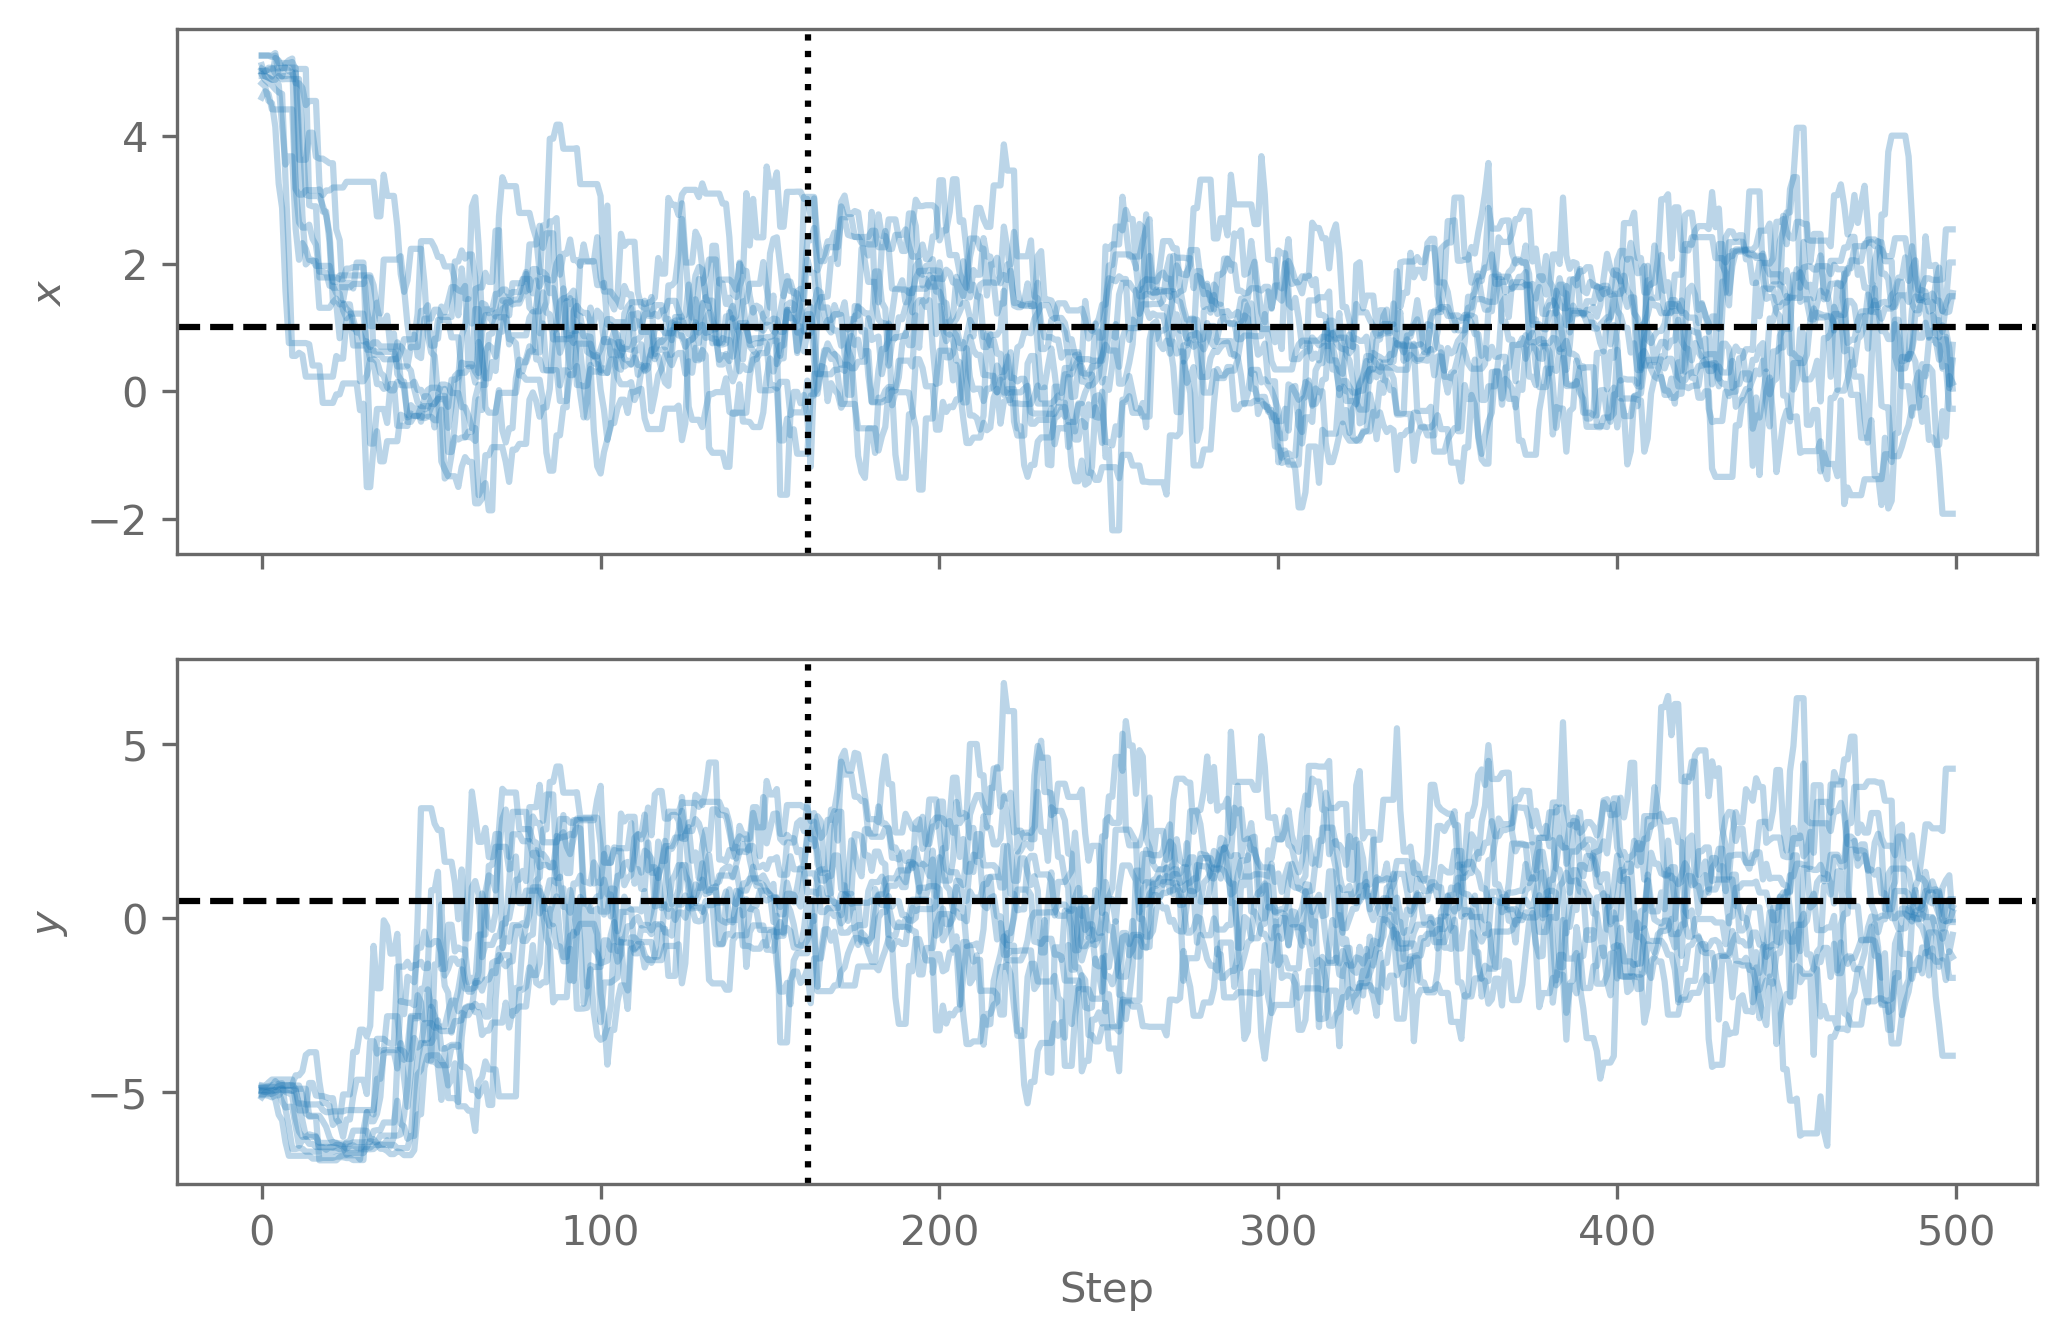

In [50]:
chain = sampler.get_chain()   # shape (n_step, n_walker, 2)

fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
for k, (ax, name) in enumerate(zip(axes, ["$x$", "$y$"])):
    ax.plot(chain[:500, :, k], c="C0", alpha=0.3)
    ax.axhline(mean[k], c="k", ls="--")
    ax.axvline(5*max(tau), c="k", ls=":")
    ax.set_ylabel(name)
axes[1].set_xlabel("Step");

The walkers start close to $(5, -5)$ and reach the bulk of the target after about 50 to 100 steps. The burn-in we removed (about 160 steps) is longer than this, so it is safe.

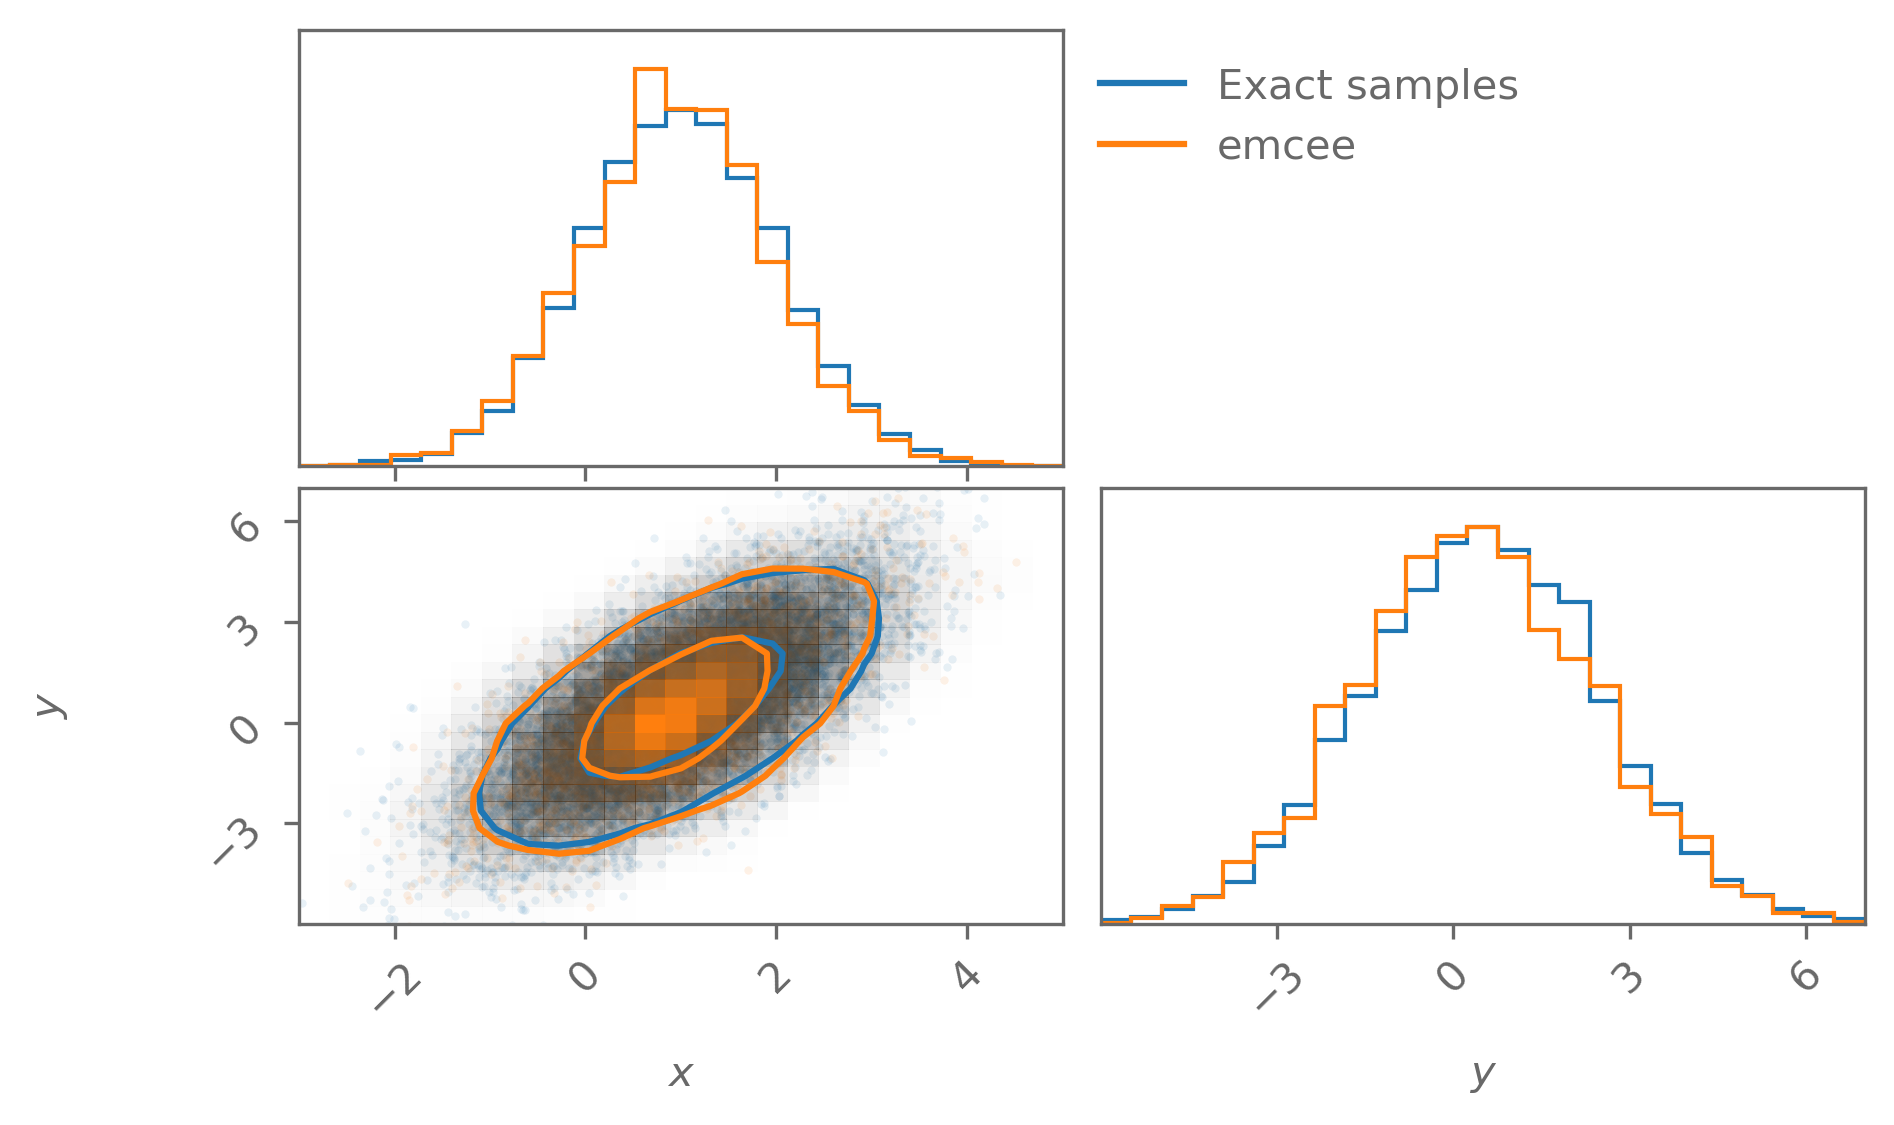

In [51]:
compare_corner([true_samples, emcee_samples], ["Exact samples", "emcee"]);

### 4.2 dynesty

`dynesty` needs a `prior_transform` that maps the unit cube to the prior. For $\mathcal{U}(-7, 7)$ this is $\theta = 14u - 7$.

In [52]:
def prior_transform_box(u):
    return 14*u - 7

dynesty_sampler = dynesty.NestedSampler(
    loglikelihood=log_L_gauss,
    prior_transform=prior_transform_box,
    ndim=2,
    nlive=500,
    rstate=np.random.default_rng(7),  # seed for reproducibility
)
dynesty_sampler.run_nested(print_progress=False)
dynesty_results = dynesty_sampler.results
dynesty_results.summary()

# Equally weighted posterior samples
dynesty_samples = dynesty_results.samples_equal()

Summary
nlive: 500
niter: 1957
ncall: 18141
eff(%): 13.544
logz: -5.264 +/-  0.131


The run plot shows how the run progressed, as a function of $-\ln X$ (the prior volume shrinks from left to right):

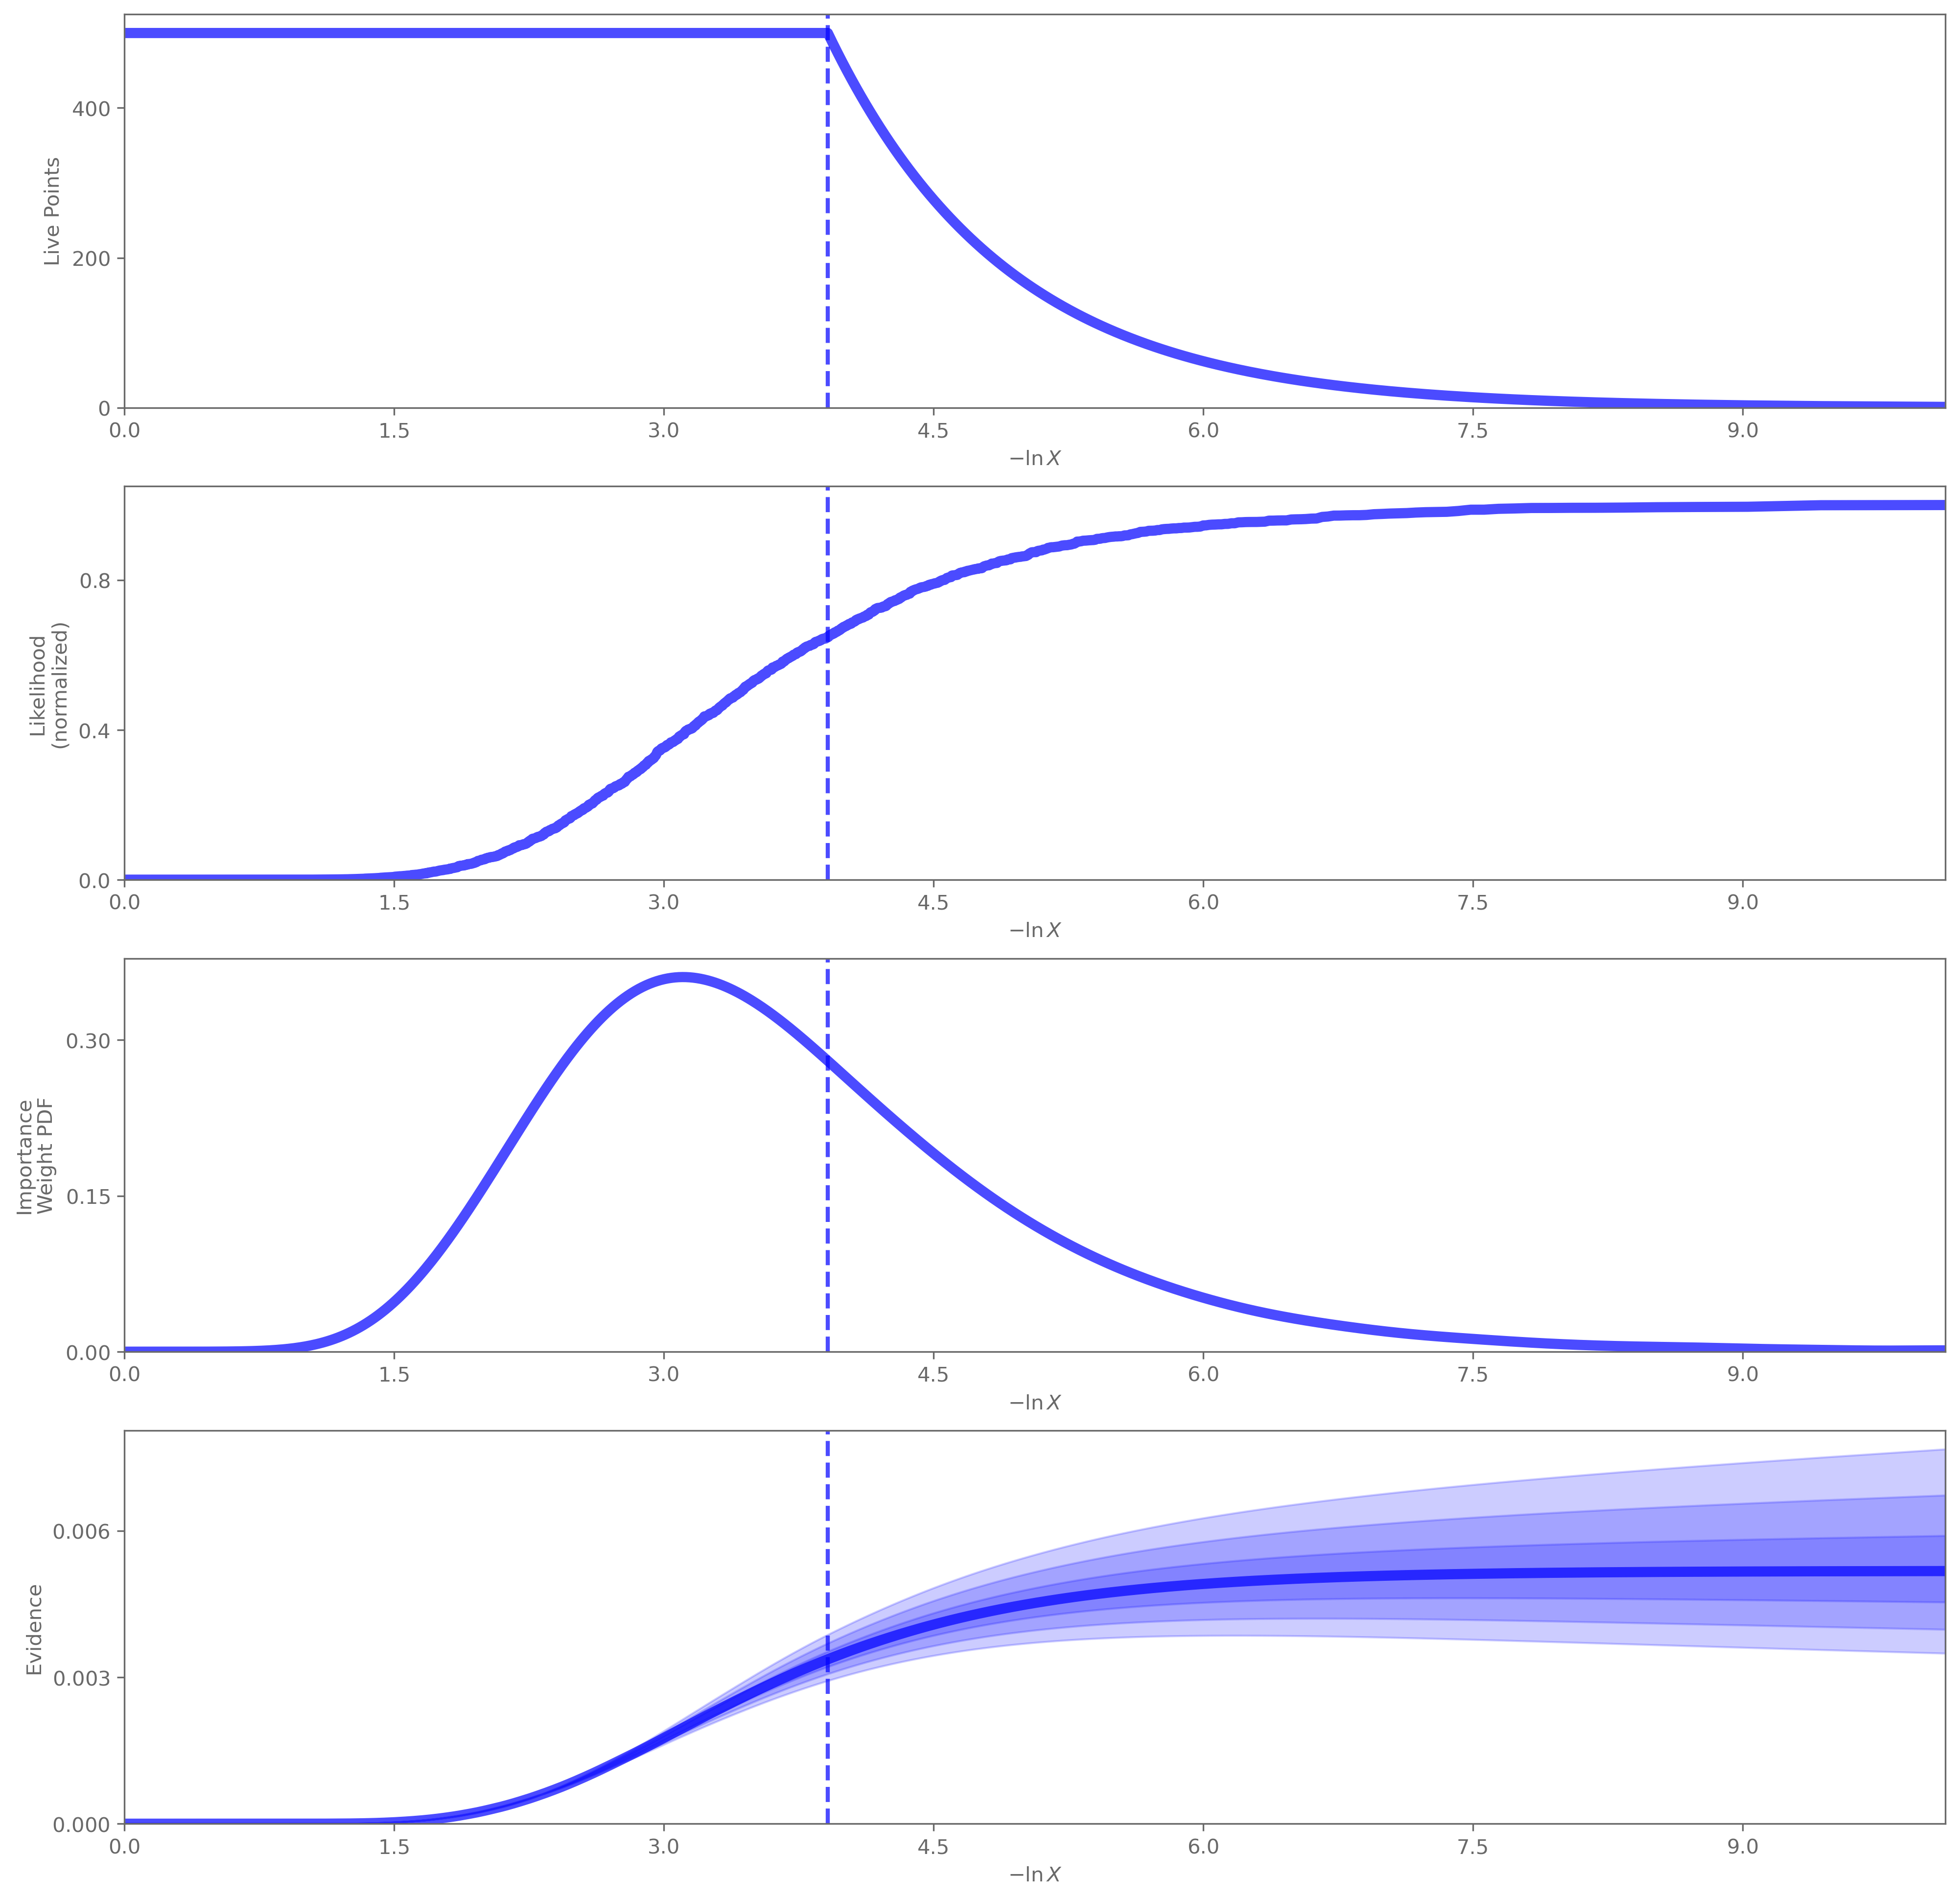

In [53]:
import dynesty.plotting
dynesty.plotting.runplot(dynesty_results);

From top to bottom:
- **Live points:** constant during the run. At the end (dashed line), the remaining live points are added one by one.
- **Likelihood** of the dead points: it increases as the prior volume shrinks towards the peak.
- **Importance weight:** how much each dead point contributes to $Z$ and to the posterior. It peaks where most of the posterior mass is.
- **Evidence:** it builds up and levels off once the remaining prior volume cannot add much more. The bands show its uncertainty.

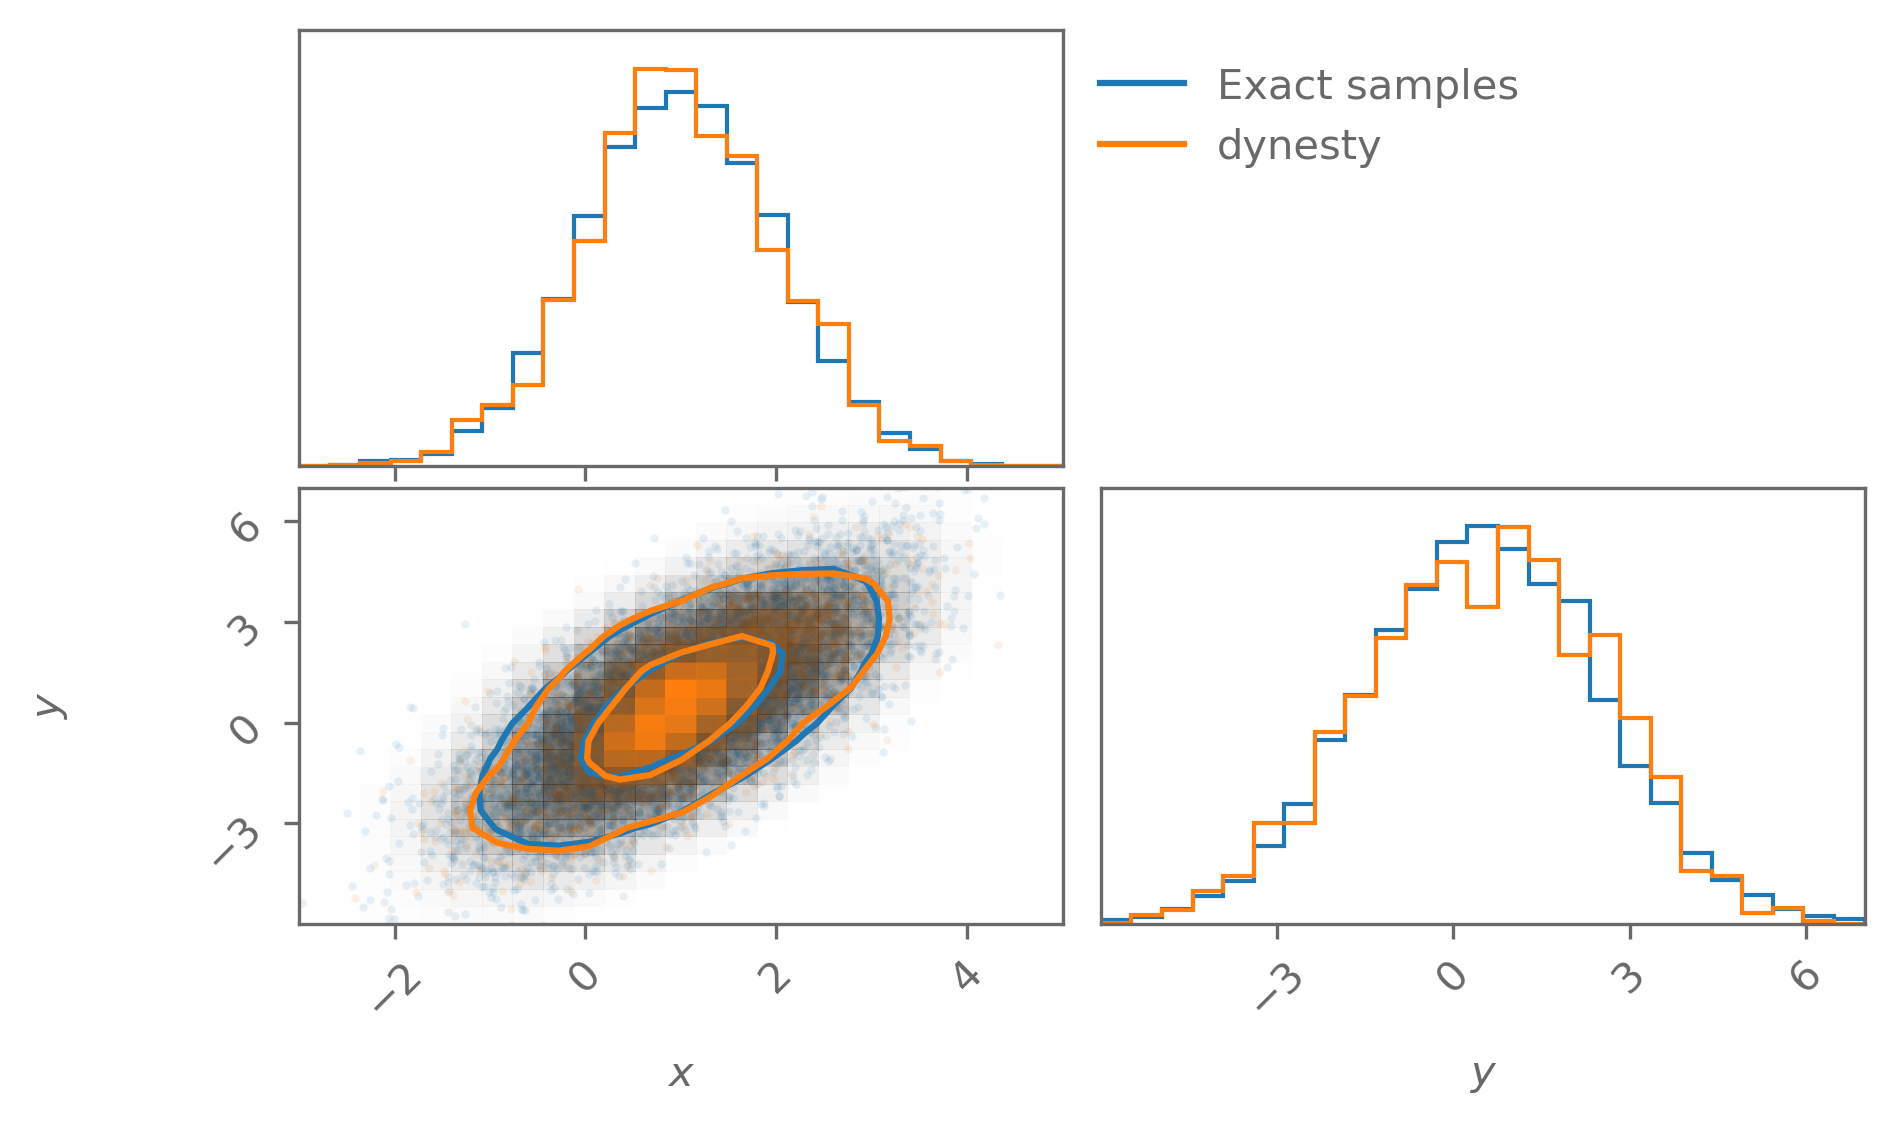

In [54]:
compare_corner([true_samples, dynesty_samples], ["Exact samples", "dynesty"]);

### 4.3 Comparison

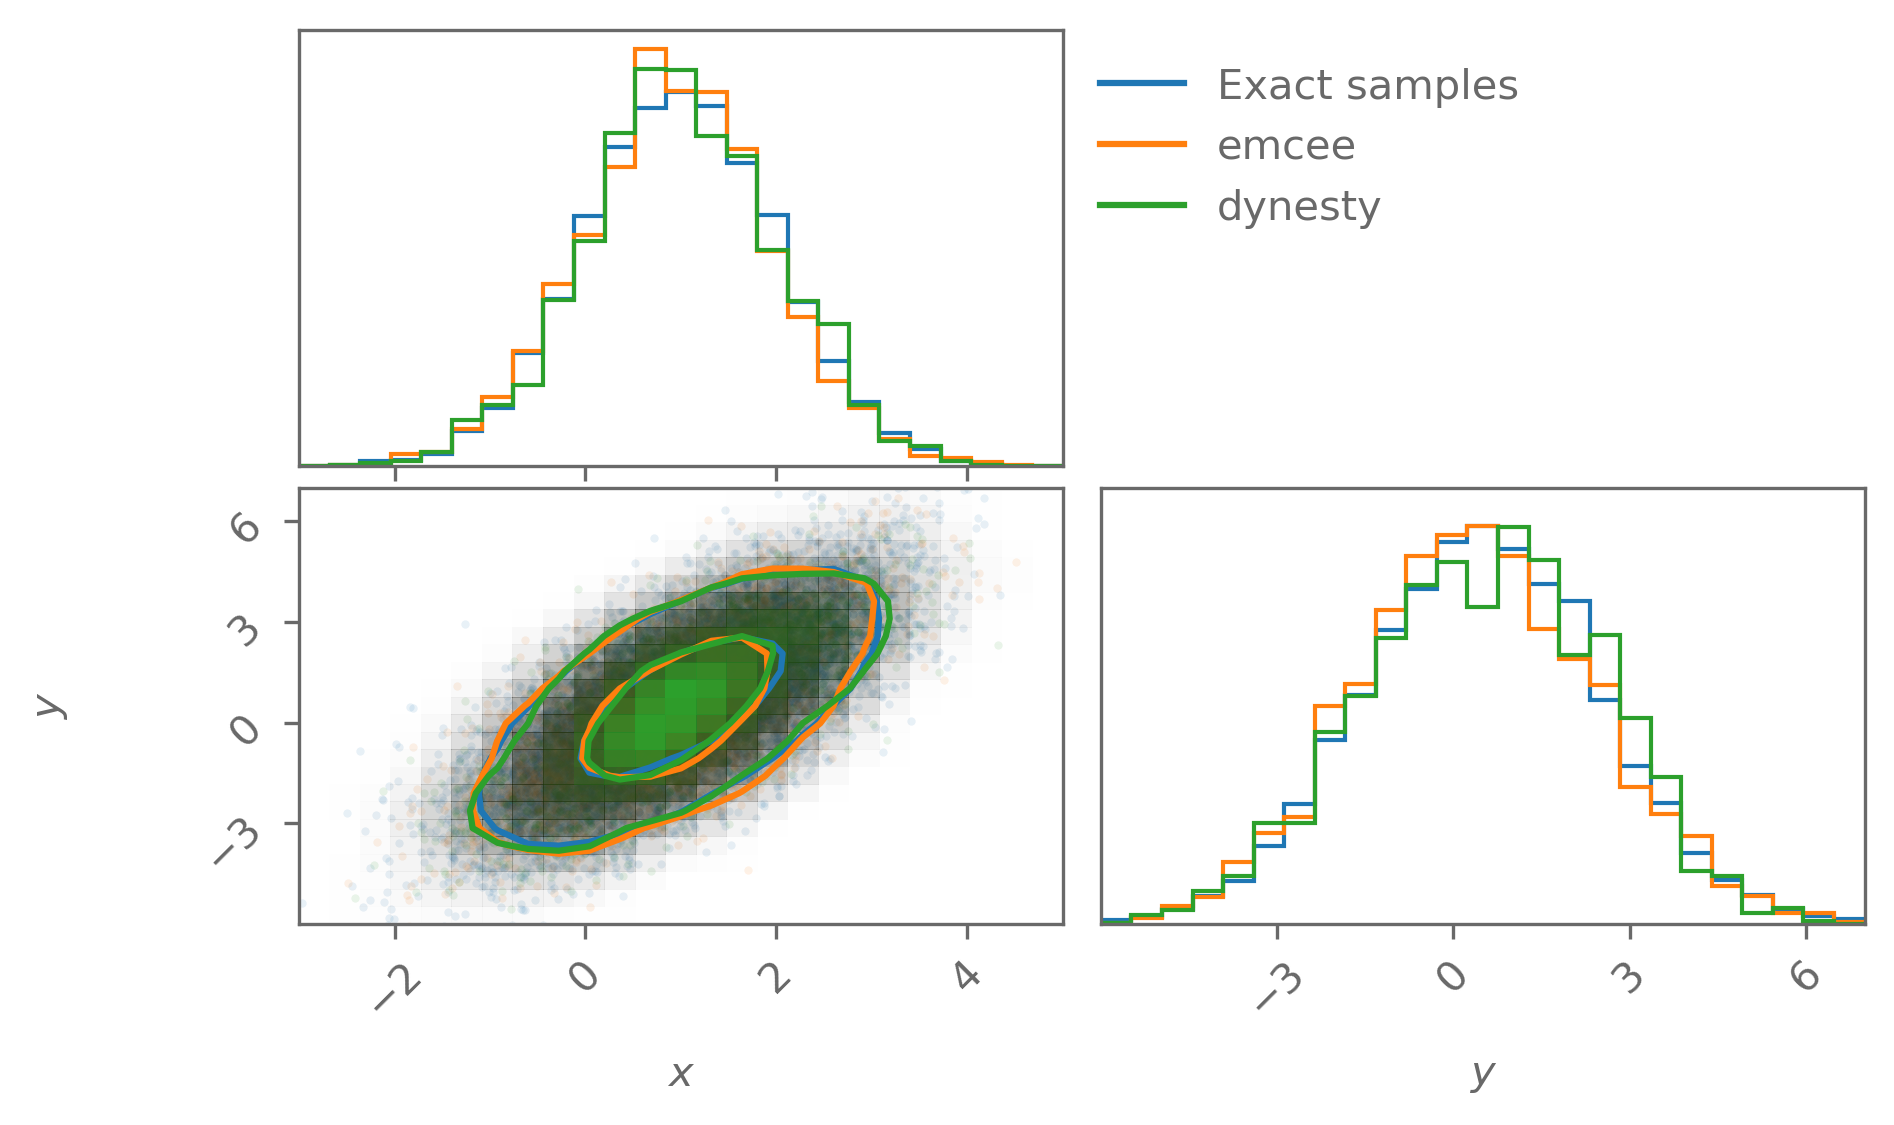

In [55]:
compare_corner(
    [true_samples, emcee_samples, dynesty_samples],
    ["Exact samples", "emcee", "dynesty"],
);

In [56]:
print(f"Exact:               ln Z = {log_Z_exact:.3f}")
print(f"Our nested sampling: ln Z = {np.mean(log_Z_runs):.3f} ± {np.std(log_Z_runs):.3f}  (10 runs)")
print(f"dynesty:             ln Z = {dynesty_results.logz[-1]:.3f} ± {dynesty_results.logzerr[-1]:.3f}")

Exact:               ln Z = -5.278
Our nested sampling: ln Z = -5.220 ± 0.083  (10 runs)
dynesty:             ln Z = -5.264 ± 0.131


All samplers agree with the exact samples, and both nested samplers find the exact $\ln Z$ within their uncertainties.

### 4.4 Number of likelihood evaluations

In [57]:
print(f"emcee:               {n_walker*5000} (no ln Z)")
print(f"dynesty:             {np.sum(dynesty_results.ncall)}")
print(f"Our nested sampling: {200 + np.sum(n_tries)}")   # n_live initial points + all tries

emcee:               50000 (no ln Z)
dynesty:             18141
Our nested sampling: 389929


`emcee` needs 50,000 evaluations and does not give $\ln Z$. `dynesty` needs about 18,000 and gives both posterior samples and $\ln Z$.

Our nested sampler needs about 390,000, more than 20 times as many as `dynesty`: rejection sampling from the full prior gets very inefficient as the prior volume shrinks. `dynesty` instead draws new points only from a region (a set of ellipsoids) around the current live points.

### 4.5 Number of live points

We run `dynesty` 10 times for each number of live points, and look at the scatter of $\ln Z$ between the runs:

In [58]:
for n_live in [50, 200, 1000]:
    log_Z_n_live, log_Z_err_n_live, n_calls = [], [], []
    for seed in range(10):
        sampler_n_live = dynesty.NestedSampler(
            loglikelihood=log_L_gauss,
            prior_transform=prior_transform_box,
            ndim=2,
            nlive=n_live,
            rstate=np.random.default_rng(20 + seed),
        )
        sampler_n_live.run_nested(print_progress=False)
        results = sampler_n_live.results
        log_Z_n_live.append(results.logz[-1])
        log_Z_err_n_live.append(results.logzerr[-1])
        n_calls.append(np.sum(results.ncall))

    print(f"n_live = {n_live:4d}: ln Z = {np.mean(log_Z_n_live):.3f}, "
          f"scatter between runs {np.std(log_Z_n_live):.3f}, "
          f"error reported by dynesty {np.mean(log_Z_err_n_live):.3f}, "
          f"{np.mean(n_calls):.0f} likelihood evaluations")

n_live =   50: ln Z = -5.276, scatter between runs 0.139, error reported by dynesty 0.227, 2105 likelihood evaluations
n_live =  200: ln Z = -5.312, scatter between runs 0.101, error reported by dynesty 0.152, 7690 likelihood evaluations
n_live = 1000: ln Z = -5.259, scatter between runs 0.046, error reported by dynesty 0.124, 27722 likelihood evaluations


With more live points, the scatter of $\ln Z$ between runs gets smaller (from about 0.14 to 0.05), but the number of likelihood evaluations grows. All three agree with the exact value $\ln Z = -5.278$ within their scatter.

The error reported by `dynesty` is larger than the actual scatter between runs, especially for many live points. Here it is a conservative estimate: repeating a run with different seeds is the most direct check.

### 4.6 emcee vs. dynesty: the evidence

*Task:* add a constant to the log posterior and run `emcee` again with the same seed. Then run `dynesty` with the prior box $[-14, 14]^2$ and compare $\ln Z$.

`emcee` only uses ratios of the posterior, $p(x')/p(x_t)$. Adding a constant to $\ln p$ multiplies $p$ by a constant, which cancels in every ratio:

In [59]:
def log_posterior_box_shifted(theta):
    return log_posterior_box(theta) + 10   # the posterior times e^10

# Same seed and same starting points as in 4.1
np.random.seed(6)
theta_init = np.array([5, -5]) + 0.1*np.random.normal(size=(n_walker, 2))

sampler_shifted = emcee.EnsembleSampler(nwalkers=n_walker, ndim=2, log_prob_fn=log_posterior_box_shifted)
sampler_shifted.run_mcmc(theta_init, nsteps=5000)

print("Identical chains:", np.array_equal(sampler.get_chain(), sampler_shifted.get_chain()))

Identical chains: True


The chain is exactly the same. `emcee` never sees the normalisation of the posterior, so it cannot tell us $Z$.

`dynesty` integrates the likelihood over the prior, so it does see the normalisation. With the box $[-14, 14]^2$ the prior density is $1/28^2$ instead of $1/14^2$, so we expect $\ln Z$ to drop by $\ln 4$:

In [60]:
def prior_transform_wide_box(u):
    return 28*u - 14

sampler_wide = dynesty.NestedSampler(
    loglikelihood=log_L_gauss,
    prior_transform=prior_transform_wide_box,
    ndim=2,
    nlive=500,
    rstate=np.random.default_rng(9),
)
sampler_wide.run_nested(print_progress=False)
results_wide = sampler_wide.results

print(f"Box [-7, 7]^2:   ln Z = {dynesty_results.logz[-1]:.3f} ± {dynesty_results.logzerr[-1]:.3f}  (exact {-np.log(14**2):.3f})")
print(f"Box [-14, 14]^2: ln Z = {results_wide.logz[-1]:.3f} ± {results_wide.logzerr[-1]:.3f}  (exact {-np.log(28**2):.3f})")

samples_wide = results_wide.samples_equal()
print("Posterior mean, box [-7, 7]^2:  ", np.mean(dynesty_samples, axis=0))
print("Posterior mean, box [-14, 14]^2:", np.mean(samples_wide, axis=0))

Box [-7, 7]^2:   ln Z = -5.264 ± 0.131  (exact -5.278)
Box [-14, 14]^2: ln Z = -6.699 ± 0.162  (exact -6.664)
Posterior mean, box [-7, 7]^2:   [1.00469831 0.49903435]
Posterior mean, box [-14, 14]^2: [0.96263727 0.45203069]


Both values of $\ln Z$ agree with the exact ones, and they differ by about $\ln 4 \approx 1.39$. The posterior means are the same within the sampling noise: making the box wider does not change the posterior, because the likelihood is (almost) zero outside the small box anyway.

So `emcee` and `dynesty` give the same posterior, but only `dynesty` gives the evidence. This is what we need for model comparison (Exercise 5).

---
## Exercise 5 (Bonus): Model comparison

### 5.1 Linear vs. quadratic model on `data_2.txt`

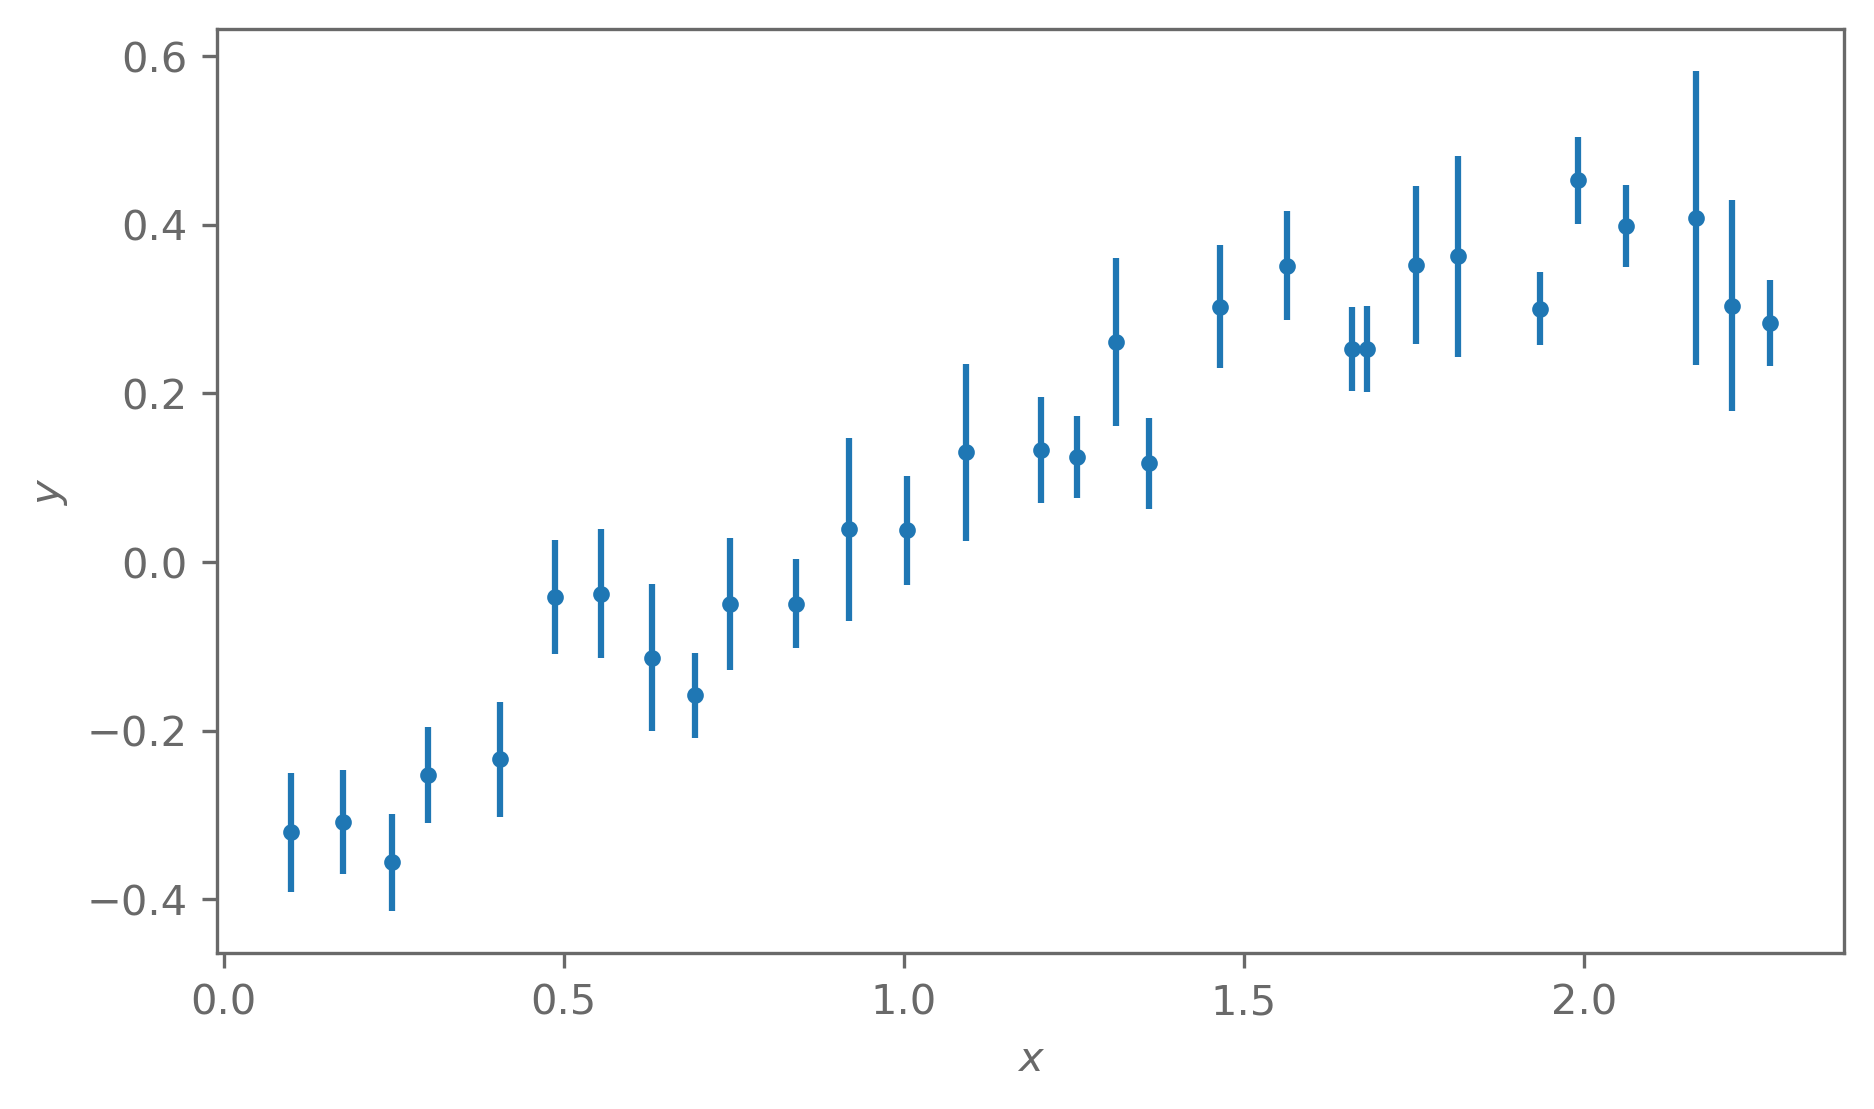

In [61]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

To compare evidences, the likelihood must be normalised, so we keep the term $-\frac{1}{2}\sum_i\ln(2\pi\sigma_{y_i}^2)$.

In [62]:
def linear_model(theta, x):
    m, b = theta
    return m*x + b

def quadratic_model(theta, x):
    a, b, c = theta
    return a*x**2 + b*x + c

def log_likelihood(theta, model, x, y, y_err):
    mu = model(theta, x)
    return (
        -0.5*np.sum((y - mu)**2/y_err**2)        # Exponent
        - 0.5*np.sum(np.log(2*np.pi*y_err**2))   # Normalisation
    )

All priors are $\mathcal{U}(-3, 3)$, so the prior transform is $\theta = 6u - 3$. A small function runs `dynesty` for a given model:

In [63]:
def prior_transform(u):
    return 6*u - 3

def run_dynesty(model, n_dim, prior_transform, x, y, y_err, seed):
    sampler = dynesty.NestedSampler(
        loglikelihood=lambda theta: log_likelihood(theta, model, x, y, y_err),
        prior_transform=prior_transform,
        ndim=n_dim,
        nlive=500,
        rstate=np.random.default_rng(seed),
    )
    sampler.run_nested(print_progress=False)
    return sampler.results

results_linear = run_dynesty(linear_model, 2, prior_transform, x, y, y_err, seed=10)
results_quadratic = run_dynesty(quadratic_model, 3, prior_transform, x, y, y_err, seed=11)

$\ln R = \ln Z_2 - \ln Z_1$. The two runs are independent, so we add their uncertainties in quadrature:

In [64]:
def bayes_ratio(results_1, results_2):
    """Print ln Z of both models and ln R = ln Z_2 - ln Z_1 with its uncertainty."""
    log_Z_1, log_Z_1_err = results_1.logz[-1], results_1.logzerr[-1]
    log_Z_2, log_Z_2_err = results_2.logz[-1], results_2.logzerr[-1]

    log_R = log_Z_2 - log_Z_1
    log_R_err = np.sqrt(log_Z_1_err**2 + log_Z_2_err**2)

    print(f"Linear:    ln Z_1 = {log_Z_1:.2f} ± {log_Z_1_err:.2f}")
    print(f"Quadratic: ln Z_2 = {log_Z_2:.2f} ± {log_Z_2_err:.2f}")
    print(f"ln R = {log_R:.2f} ± {log_R_err:.2f}, R = {np.exp(log_R):.1f}")

bayes_ratio(results_linear, results_quadratic)

Linear:    ln Z_1 = 21.61 ± 0.25
Quadratic: ln Z_2 = 23.51 ± 0.30
ln R = 1.90 ± 0.39, R = 6.7


50 posterior samples of each model on top of the data:

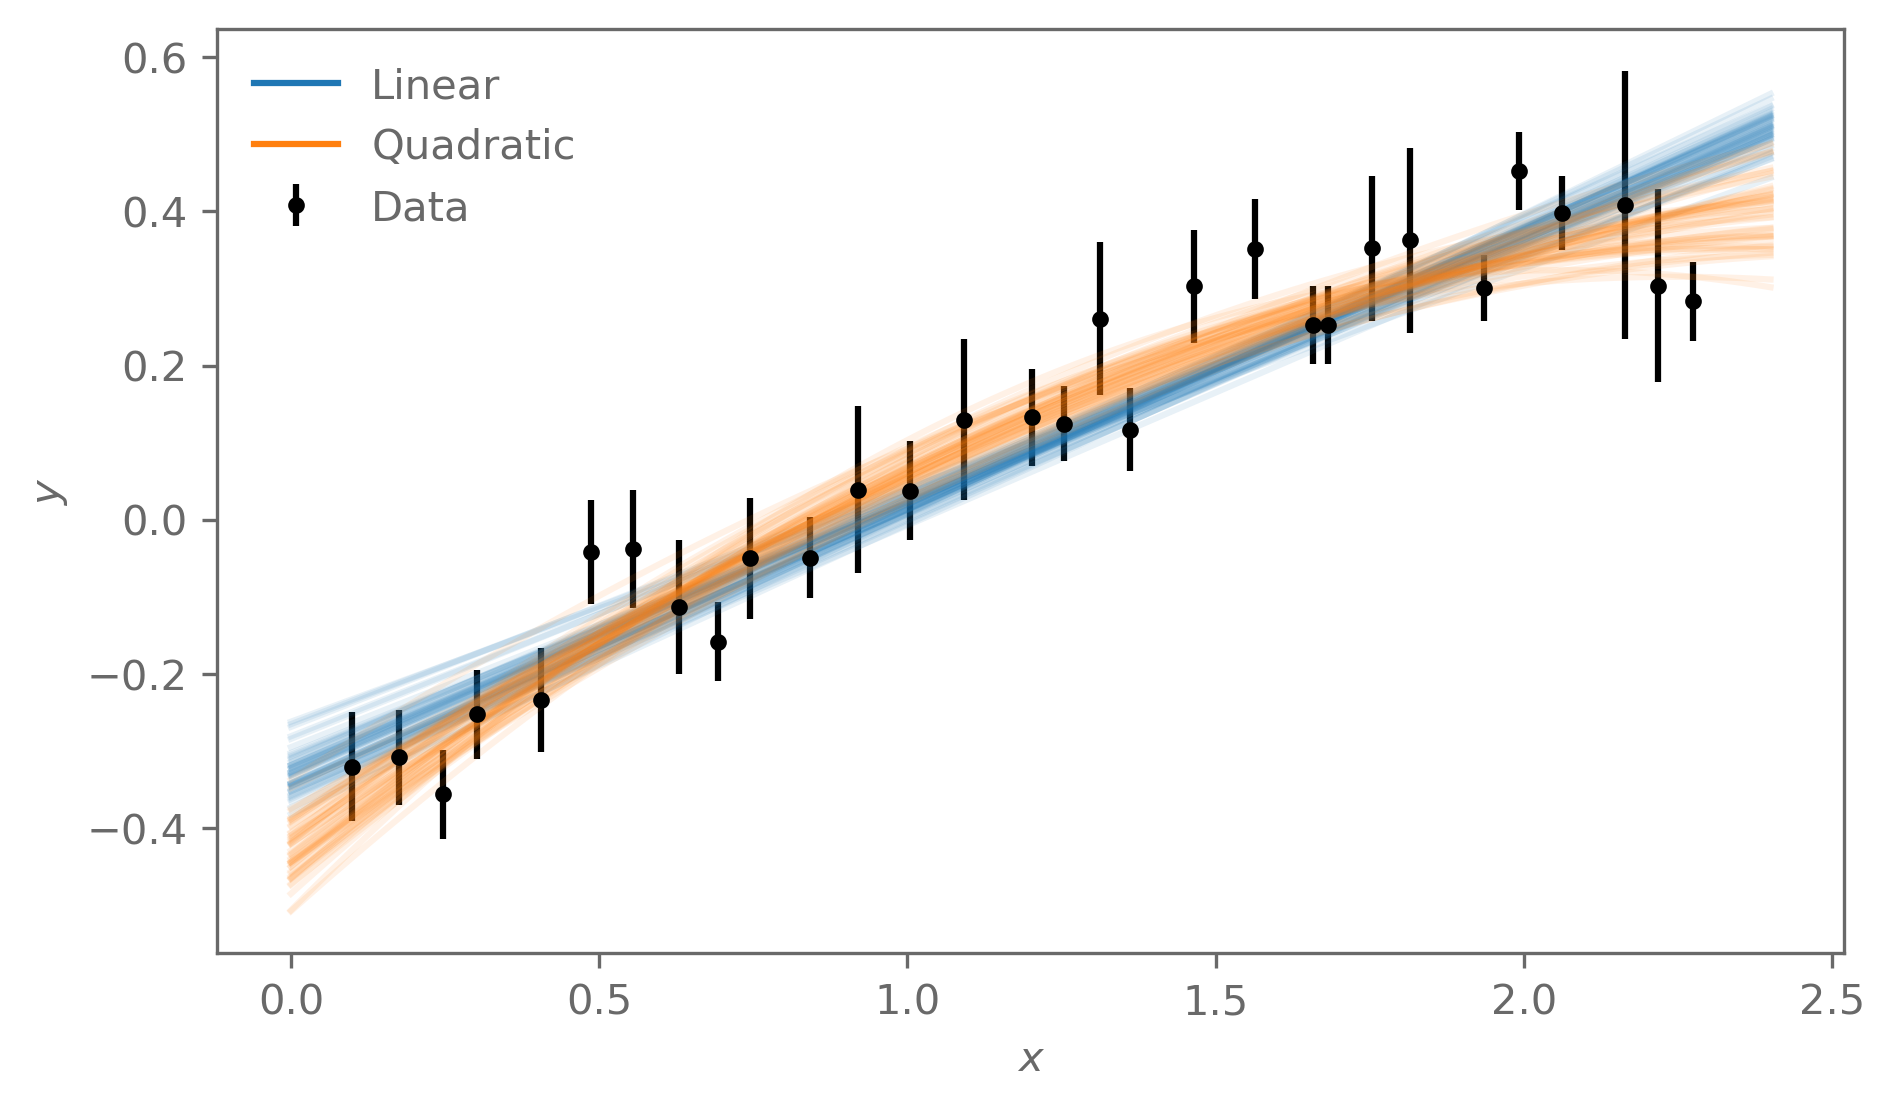

In [65]:
def plot_posterior_models(results_1, results_2, x, y, y_err):
    x_grid = np.linspace(0, 2.4, 100)
    plt.errorbar(x, y, y_err, fmt=".", c="k", label="Data")
    for results, model, color, label in [
        (results_1, linear_model, "C0", "Linear"),
        (results_2, quadratic_model, "C1", "Quadratic"),
    ]:
        samples = results.samples_equal()
        for theta in samples[:50]:
            plt.plot(x_grid, model(theta, x_grid), c=color, alpha=0.1)
        plt.plot([], [], c=color, label=label)
    plt.xlabel("$x$")
    plt.ylabel("$y$")
    plt.legend(frameon=False)

plot_posterior_models(results_linear, results_quadratic, x, y, y_err)

The quadratic model is preferred, with odds of about 7 to 1 ($R\approx 7$). With an uncertainty of about 0.4 on $\ln R$, this is a clear but not overwhelming preference.

In the plot, the quadratic model follows the bend in the data at small and large $x$.

### 5.2 Linear vs. quadratic model on `data_0.txt`

Linear:    ln Z_1 = -8.31 ± 0.20
Quadratic: ln Z_2 = -10.61 ± 0.24
ln R = -2.30 ± 0.31, R = 0.1


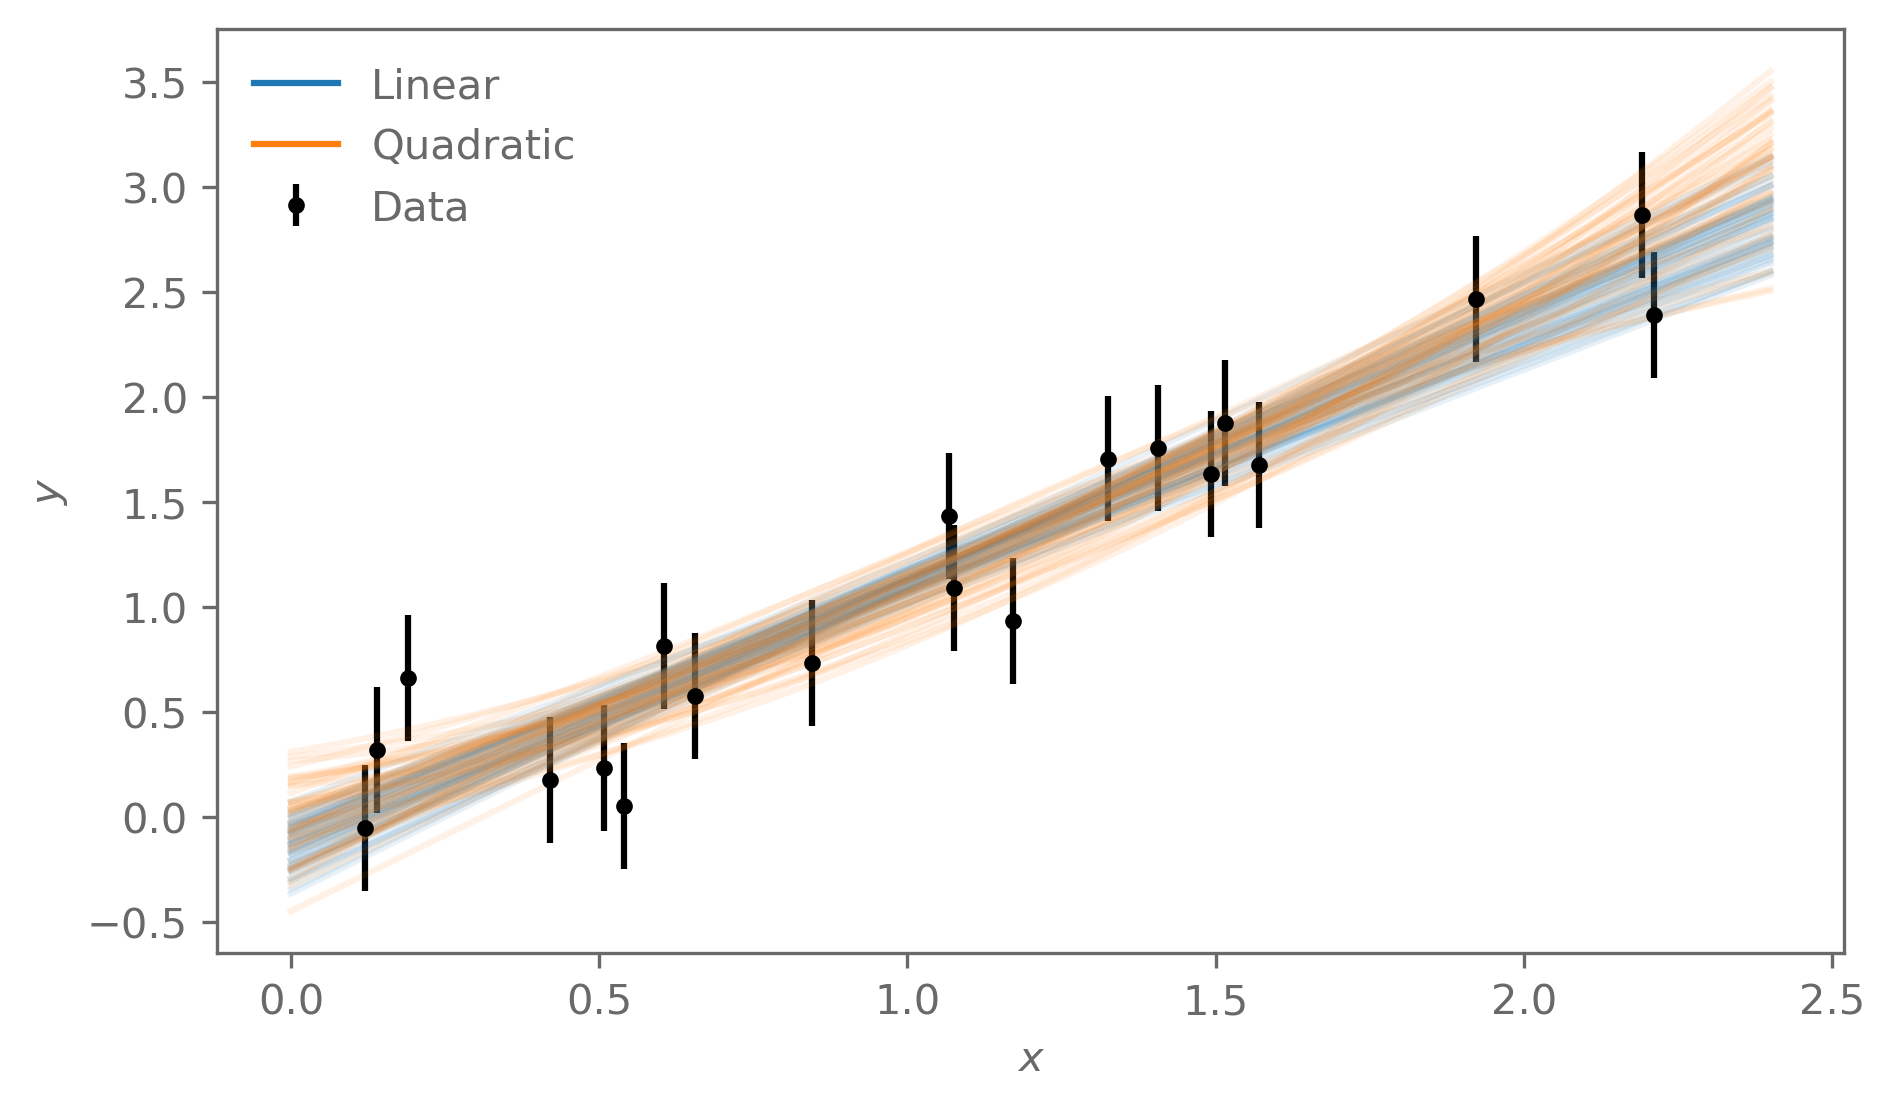

In [66]:
x_0, y_0, y_err_0 = np.loadtxt("../lectures/data/linear_fits/data_0.txt", unpack=True)

results_linear_0 = run_dynesty(linear_model, 2, prior_transform, x_0, y_0, y_err_0, seed=12)
results_quadratic_0 = run_dynesty(quadratic_model, 3, prior_transform, x_0, y_0, y_err_0, seed=13)

bayes_ratio(results_linear_0, results_quadratic_0)
plot_posterior_models(results_linear_0, results_quadratic_0, x_0, y_0, y_err_0)

Now the linear model is preferred, with odds of about 10 to 1.

The quadratic model fits these data just as well (its posterior on $a$ is consistent with 0), but it spreads its prior over many values of $a$ that do not fit the data. The evidence penalises this extra freedom (Occam's razor).

### 5.3 A wider prior on $a$

The prior on $a$ is now $\mathcal{U}(-30, 30)$; $b$ and $c$ keep $\mathcal{U}(-3, 3)$. Only $Z_2$ changes.

In [67]:
def prior_transform_wide_a(u):
    theta = 6*u - 3              # b and c: U(-3, 3)
    theta[0] = 60*u[0] - 30      # a: U(-30, 30)
    return theta

results_quadratic_wide = run_dynesty(quadratic_model, 3, prior_transform_wide_a, x, y, y_err, seed=14)

bayes_ratio(results_linear, results_quadratic_wide)

Linear:    ln Z_1 = 21.61 ± 0.25
Quadratic: ln Z_2 = 20.85 ± 0.32
ln R = -0.76 ± 0.41, R = 0.5


Did the posterior change?

In [68]:
samples_narrow = results_quadratic.samples_equal()
samples_wide = results_quadratic_wide.samples_equal()

for k, name in enumerate(["a", "b", "c"]):
    print(f"{name}: narrow prior {np.mean(samples_narrow[:, k]):.3f} ± {np.std(samples_narrow[:, k]):.3f}, "
          f"wide prior {np.mean(samples_wide[:, k]):.3f} ± {np.std(samples_wide[:, k]):.3f}")

print(f"Change in ln Z_2: {results_quadratic_wide.logz[-1] - results_quadratic.logz[-1]:.2f}")
print(f"-ln(10) = {-np.log(10):.2f}")

a: narrow prior -0.105 ± 0.031, wide prior -0.105 ± 0.032
b: narrow prior 0.599 ± 0.076, wide prior 0.598 ± 0.077
c: narrow prior -0.434 ± 0.038, wide prior -0.434 ± 0.040
Change in ln Z_2: -2.66
-ln(10) = -2.30


The posterior does not change, but $\ln Z_2$ drops by about $\ln 10$ (within the uncertainty of about 0.4). The prior on $a$ is 10 times wider, so the prior density where the likelihood is large is 10 times smaller ($Z\propto 1/V$, see the lecture).

Now the linear model is weakly preferred. The Bayes' ratio depends on the prior, even when the posterior does not, so priors have to be chosen carefully when comparing models.